# 06 · Generación de audio y de vídeo

Este es un módulo de Neural Networks 1002. Supone conocidos el [módulo 05 de Neural Networks 1002](https://neural-networks-1002.academy.forwardforecasting.eu/es/05-modelos-de-difusion/) (modelos de difusión), el [módulo 04 de Neural Networks 1002](https://neural-networks-1002.academy.forwardforecasting.eu/es/04-autoencoders-gans-y-autosupervisado/) (autoencoders y códigos latentes discretos), el [módulo 05 de Neural Networks 1001](https://neural-networks.academy.forwardforecasting.eu/es/05-redes-convolucionales/) (convoluciones) y el [módulo 09 de Neural Networks 1001](https://neural-networks.academy.forwardforecasting.eu/es/09-transformer/) (el Transformer).

Una imagen es una cuadrícula. El **sonido** es una lista larguísima de números (16.000 o más por segundo) en la que casi todo lo interesante vive a dos escalas de tiempo a la vez: unos pocos milisegundos (el tono y el timbre) y unos pocos segundos (una melodía, una frase). El **vídeo** es una pila de imágenes en la que un mismo objeto debe seguir siendo el mismo objeto de un fotograma al siguiente. Ambos problemas son difíciles por la misma razón: los datos son enormes y están muy estructurados en el tiempo. El campo los resolvió con el truco de este módulo: **no generar la señal en bruto; generar una representación compacta (un espectrograma, una secuencia de códigos discretos, un latente espacio-temporal) y decodificarla**.

Una advertencia honesta antes de empezar. Un portátil (o incluso la máquina de 32 núcleos que ejecuta este cuaderno) no puede entrenar un generador de audio o de vídeo que alguien quisiera escuchar o ver. Por eso cada tema tiene dos partes: un **juguete construido desde cero** que muestra el mecanismo y permite *medirlo*, y un **modelo real preentrenado** ejecutado en la CPU para ver lo que hace de verdad. Los juguetes de vídeo son solo ilustrativos: formas diminutas que se mueven, no vídeo natural.

En este cuaderno vas a:

* sintetizar sonidos en código y mirarlos como **forma de onda**, **STFT** (short-time Fourier transform, transformada de Fourier de tiempo corto), **espectrograma mel** y como los **tokens discretos** de un códec neuronal de audio real (EnCodec), con una tabla medida de tasa de bits frente a calidad;
* implementar a mano la recuperación de fase de **Griffin-Lim** y compararla con un **vocoder neuronal preentrenado (HiFi-GAN)** sobre la misma señal;
* entrenar, con sonidos de batería y de tonos generados, un **modelo autoregresivo sobre tokens discretos** y un pequeño **modelo de difusión sobre espectrogramas**, y compararlos con un clasificador de tipo de sonido y una **distancia de Fréchet**;
* generar unos segundos de música con un **modelo real preentrenado (MusicGen small)** a partir de texto y mirarlos con ojo crítico, y después discutir cómo **evaluar** el audio generado (distancia de Fréchet de audio, pruebas de escucha);
* entrenar un **predictor del siguiente fotograma** y un pequeño **modelo de difusión de vídeo** con convoluciones espacio-temporales sobre formas en movimiento, y medir la **consistencia temporal** (parpadeo y error de deformación por flujo óptico) con y sin capas temporales;
* usar una **red preentrenada de flujo óptico (RAFT)** para interpolar fotogramas y un **clasificador de vídeo preentrenado (R(2+1)D)** para ver qué capturan las características espacio-temporales que no capturan las de cada fotograma por separado;
* leer la **arquitectura de los sistemas de texto a vídeo al estilo Sora** con recuento de tokens, y terminar con **procedencia y seguridad**: una marca de agua de audio de juguete que funciona, deepfakes, consentimiento y derechos de autor.

**Contenido**

1. Preparación y una caja de sonidos sintéticos
2. Cómo se representa el sonido: forma de onda, STFT, espectrograma mel, tokens de códec
3. Del espectrograma de vuelta a la forma de onda: Griffin-Lim y un vocoder neuronal
4. Dos familias de generadores de audio sobre un conjunto de sonidos de juguete
5. Un modelo real de texto a música: MusicGen small
6. Evaluar el audio generado
7. El vídeo son fotogramas más tiempo
8. Generación de vídeo de juguete: predicción del siguiente fotograma y difusión de vídeo
9. Modelos preentrenados de movimiento: RAFT y un clasificador de vídeo
10. Texto a vídeo moderno: Transformers de difusión sobre parches latentes espacio-temporales
11. Procedencia, marcas de agua y seguridad
12. Ideas clave, ejercicios, referencias

| Se apoya en | Qué reutilizamos |
|---|---|
| [05 Modelos de difusión (1002)](https://neural-networks-1002.academy.forwardforecasting.eu/es/05-modelos-de-difusion/) | la receta de añadir y quitar ruido; aquí aplicada a espectrogramas y a tensores espacio-temporales |
| [04 Autoencoders, GAN y aprendizaje autosupervisado (1002)](https://neural-networks-1002.academy.forwardforecasting.eu/es/04-autoencoders-gans-y-autosupervisado/) | cuellos de botella y códigos discretos; un códec neuronal de audio es un autoencoder con un cuantizador; HiFi-GAN es una GAN |
| [05 Redes convolucionales (1001)](https://neural-networks.academy.forwardforecasting.eu/es/05-redes-convolucionales/) | convoluciones 2D, que extendemos a convoluciones 3D (espacio-tiempo) |
| [09 El Transformer (1001)](https://neural-networks.academy.forwardforecasting.eu/es/09-transformer/) | la atención, cuyo coste crece con el cuadrado del número de tokens: la restricción central del vídeo |

¿Nuevo en PyTorch? Mira la [sección sobre marcos de IA del curso Python 1001](https://python.academy.forwardforecasting.eu/es/11-frameworks-de-ia/). **Tiempo de ejecución y Colab.** El cuaderno se ejecuta solo en CPU, sin GPU y sin claves. Medido en una máquina de 32 vCPU del clúster limitada a 2 hilos (lo mismo que un entorno gratuito de Google Colab, que tiene 2 vCPU): unos 9 minutos con los modelos ya en caché (17 minutos la primera vez, con las descargas), de los cuales las partes mayores son la difusión de audio (unos 100 s), los dos modelos gemelos de difusión de vídeo (unos 200 s con las mediciones por flujo óptico), los clips reales de MusicGen (unos 35 s) y las características del clasificador de vídeo (unos 60 s); una CPU de Colab más lenta puede tardar bastante más. Los paquetes usados (NumPy, SciPy, pandas, scikit-learn, matplotlib, PyTorch, torchvision, transformers) vienen preinstalados en Colab; no se instala nada más. **Descargas** (una vez, luego en caché): EnCodec 24 kHz (unos 90 MB), el vocoder HiFi-GAN de SpeechT5 (unos 50 MB), MusicGen small (unos 2,4 GB), RAFT small (4 MB) y R(2+1)D-18 (120 MB). **Dónde difieren los juguetes de los sistemas reales:** los generadores reales de audio y de vídeo se entrenan durante semanas con decenas de miles de horas de audio o millones de clips en cientos de GPU; nuestros sonidos duran medio segundo y nuestros vídeos son de 16 por 16 píxeles, así que los números muestran mecanismos y direcciones de efectos, no calidad de producción.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/fborbon/academy/blob/main/neural-networks-1002/es/06_generacion_de_audio_y_video.ipynb)

**¿Lo ejecutas en Google Colab?** Elige *Entorno de ejecución > Ejecutar todo*. La primera celda de código instala solo lo que falta (no hace falta reiniciar la sesión). **Tiempo medido** en un entorno limpio de 2 CPU como el de Colab: unos 17 minutos, con un pico de memoria de unos 5,8 GB (las descargas de modelos y datos se hicieron con una conexión rápida). Una CPU gratuita de Colab suele ser más lenta que la máquina usada para medir, así que cuenta con más tiempo; los tiempos impresos en las salidas guardadas vienen de una máquina con varios núcleos.

In [ ]:
# Preparación: funciona en local y en Google Colab. Instala solo los paquetes que faltan.
import importlib.util, os, subprocess, sys

IN_COLAB = 'google.colab' in sys.modules
_NEEDED = {
    'matplotlib': 'matplotlib',
    'numpy': 'numpy',
    'pandas': 'pandas',
    'scipy': 'scipy',
    'sklearn': 'scikit-learn',
    'torch': 'torch',
    'torchvision': 'torchvision',
    'transformers': 'transformers',
}  # import name -> pip requirement
_missing = [req for mod, req in _NEEDED.items() if importlib.util.find_spec(mod) is None]
if _missing:
    print('Instalando:', ', '.join(_missing))
    _r = subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', *_missing], capture_output=True, text=True)
    if _r.returncode:
        print('ADVERTENCIA: la instalación con pip falló; se continúa. Detalle:\n' + _r.stderr[-400:])
print(f"Entorno: Python {sys.version.split()[0]} | {'Google Colab' if IN_COLAB else 'local'} | CPUs: {os.cpu_count()}")

## 1. Preparación y una caja de sonidos sintéticos

Escribimos nuestro propio sintetizador pequeño (solo NumPy) para que todos los sonidos de este cuaderno sean generados, con semillas fijas y sin datos que descargar. Una **frecuencia de muestreo** (SR, sample rate) de 16.000 muestras por segundo significa que la señal se guarda como 16.000 números por segundo y puede representar frecuencias hasta SR/2 = 8.000 Hz (el límite de **Nyquist**). El sintetizador hace cuatro piezas básicas: una **nota armónica** (una frecuencia fundamental $f_0$ más sus múltiplos enteros, los armónicos, cada uno más débil que el anterior), un **bombo** (un seno cuyo tono cae rápido), una **caja** (un tono corto más ruido que decae) y un **hi-hat** (ruido filtrado pasa-altos con un decaimiento muy rápido).

Los reproductores de audio de abajo son elementos HTML de audio normales con el sonido incrustado en el cuaderno (los clips duran uno o dos segundos), así que funcionan en una copia descargada o estática del cuaderno. Si tu visor los elimina, los gráficos de espectrogramas llevan la misma información.

In [1]:
import warnings, os, time, math, io
warnings.filterwarnings("ignore")
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import scipy.signal as sps
import torch, torch.nn as nn, torch.nn.functional as F
import transformers
transformers.logging.set_verbosity_error()
from IPython.display import Audio, display

NT = max(1, min(8, int(os.environ.get("OMP_NUM_THREADS", os.cpu_count() or 2))))     # a free Colab runtime has 2 cores
torch.set_num_threads(NT)
torch.manual_seed(0); np.random.seed(0)
plt.rcParams["axes.grid"] = False
plt.rcParams["figure.dpi"] = 90
T0 = time.time()
LAP = {}
def lap(name, t0):
    LAP[name] = time.time() - t0
    print(f"[{name}: {LAP[name]:.0f} s]")

SR = 16000

def play(x, sr, label):
    x = np.asarray(x, dtype=np.float32)
    x = 0.9 * x / (np.abs(x).max() + 1e-9)
    print(label)
    display(Audio(x, rate=sr))

def harmonic(f0, dur, sr=SR, n_harm=6, tau=0.4, vib=0.0):
    t = np.arange(int(dur * sr)) / sr
    f = f0 * (1 + vib * np.sin(2 * np.pi * 5 * t))
    ph = 2 * np.pi * np.cumsum(f) / sr
    y = sum(np.sin(h * ph) / h for h in range(1, n_harm + 1) if h * f0 < sr / 2)
    return y * np.minimum(1, t / 0.01) * np.exp(-t / tau)

def kick(n, f_hi=130, f_lo=45, tau=0.12, sr=SR):
    t = np.arange(n) / sr
    f = f_lo + (f_hi - f_lo) * np.exp(-t / 0.03)
    return np.sin(2 * np.pi * np.cumsum(f) / sr) * np.exp(-t / tau)

def snare(n, rng, f0=190, tau=0.09, noise=0.8, sr=SR):
    t = np.arange(n) / sr
    return 0.5 * np.sin(2 * np.pi * f0 * t) * np.exp(-t / 0.05) + noise * rng.standard_normal(n) * np.exp(-t / tau)

SOS_HP = sps.butter(6, 5500, "highpass", fs=SR, output="sos")
def hat(n, rng, tau=0.03, sr=SR):
    t = np.arange(n) / sr
    return sps.sosfilt(SOS_HP, rng.standard_normal(n)) * np.exp(-t / tau)

def chirp(n, f_a, f_b, tau, sr=SR):
    t = np.arange(n) / sr
    f = f_a + (f_b - f_a) * t / (n / sr)
    return np.sin(2 * np.pi * np.cumsum(f) / sr) * np.exp(-t / tau)

def place(track, sound, start):
    track[start:start + len(sound)] += sound[:len(track) - start]

# one 1.5 second demo clip: three notes, two kicks, a snare and some hi-hats
rng = np.random.default_rng(0)
demo = np.zeros(int(1.5 * SR))
for i, f0 in enumerate([262, 330, 392]):
    place(demo, 0.5 * harmonic(f0, 0.6, vib=0.01), int(i * 0.5 * SR))
place(demo, 1.2 * kick(4000), 0); place(demo, 1.2 * kick(4000), int(0.75 * SR))
place(demo, 0.8 * snare(3000, rng), int(0.375 * SR)); place(demo, 0.8 * snare(3000, rng), int(1.125 * SR))
for k in range(6):
    place(demo, 0.3 * hat(1500, rng), int(k * 0.25 * SR))
demo = (demo / np.abs(demo).max() * 0.9).astype(np.float32)
print("clip de demostración:", len(demo), "muestras =", len(demo) / SR, "s")
play(demo, SR, "clip de demostración (notas, bombos, cajas, hi-hats)")

clip de demostración: 24000 muestras = 1.5 s
clip de demostración (notas, bombos, cajas, hi-hats)


## 2. Cómo se representa el sonido: forma de onda, STFT, espectrograma mel, tokens de códec

Cuatro representaciones del mismo sonido, de la más cruda a la más compacta:

1. **Forma de onda**: la presión del aire muestreada 16.000 veces por segundo. Es completa, pero la estructura que oímos (tono, timbre) está repartida entre miles de números vecinos, así que un generador que trabaja muestra a muestra (WaveNet, [van den Oord et al., 2016](https://arxiv.org/abs/1609.03499)) debe ser muy profundo y es lento.
2. **STFT** (short-time Fourier transform, transformada de Fourier de tiempo corto): se corta la señal en ventanas cortas solapadas de $N$ muestras, se multiplica cada una por una ventana suave (aquí la de Hann) y se toma la transformada de Fourier. El resultado es un número complejo para cada par (frecuencia, tiempo): su **magnitud** dice cuánta energía hay, su **fase** dice en qué punto de su ciclo está la onda. Dibujamos la magnitud en decibelios (dB), $20\log_{10}|S|$. Hay un **compromiso**: una ventana larga ($N$ grande) separa frecuencias cercanas pero difumina los eventos en el tiempo, y una ventana corta hace lo contrario (es el principio de incertidumbre de Heisenberg-Gabor de las señales).
3. **Espectrograma mel**: se suma la energía de la STFT de frecuencias vecinas en unas pocas decenas de bandas espaciadas según la **escala mel**, que sigue cómo oímos (resolución fina en bajas frecuencias, gruesa en altas), y después se toma el logaritmo, porque la percepción de la sonoridad es logarítmica. Descarta la fase y reduce mucho los datos. La mayoría de los modelos de "audio como imagen" (y la entrada de la mayoría de los reconocedores de voz) usan el mel.
4. **Tokens de un códec neuronal**: un codificador (un autoencoder convolucional) comprime la forma de onda en una secuencia de vectores a baja frecuencia (75 fotogramas por segundo en EnCodec), y la **cuantización vectorial residual** (RVQ, residual vector quantisation) sustituye cada vector por unos pocos enteros: el primer libro de códigos elige la entrada más cercana de una tabla de 1.024 vectores, el segundo cuantiza lo que el primero no captó, y así sucesivamente. El resultado es una **cuadrícula de enteros** (libros de códigos por fotogramas) que un modelo de lenguaje puede predecir como si fuera texto, y que un decodificador convierte de nuevo en sonido. Es la representación detrás de AudioLM ([Borsos et al., 2022](https://arxiv.org/abs/2209.03143)) y de MusicGen.

Primero implementamos nosotros la STFT y el banco de filtros mel (unas pocas líneas de NumPy) y comprobamos que la STFT es invertible si conservamos la fase.

forma de la STFT (513, 94) forma del mel (64, 94)
error máximo de reconstrucción con magnitud Y fase: 3.3306690738754696e-16


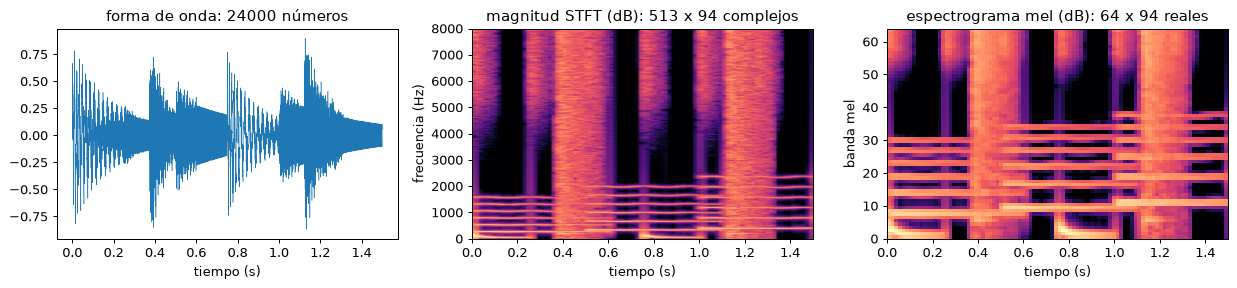

In [2]:
def stft(x, n_fft=1024, hop=256):
    w = np.hanning(n_fft + 1)[:-1]
    xp = np.pad(x, (n_fft // 2, n_fft // 2), mode="reflect")
    n = 1 + (len(xp) - n_fft) // hop
    idx = np.arange(n_fft)[None, :] + hop * np.arange(n)[:, None]
    return np.fft.rfft(xp[idx] * w, axis=1).T            # shape (frequencies, frames)

def istft(S, n_fft=1024, hop=256):
    w = np.hanning(n_fft + 1)[:-1]
    fr = np.fft.irfft(S.T, n=n_fft, axis=1) * w
    n = fr.shape[0]
    out = np.zeros(hop * (n - 1) + n_fft); ws = np.zeros_like(out)
    for i in range(n):
        out[i * hop:i * hop + n_fft] += fr[i]; ws[i * hop:i * hop + n_fft] += w ** 2
    return (out / np.maximum(ws, 1e-8))[n_fft // 2:-(n_fft // 2)]

def hz2mel(f): return 2595 * np.log10(1 + f / 700)

def mel_fb(sr, n_fft, n_mels, fmin=0.0, fmax=None):
    fmax = fmax or sr / 2
    pts = 700 * (10 ** (np.linspace(hz2mel(fmin), hz2mel(fmax), n_mels + 2) / 2595) - 1)
    bins = np.fft.rfftfreq(n_fft, 1 / sr)
    fb = np.zeros((n_mels, len(bins)))
    for i in range(n_mels):
        l, c, r = pts[i:i + 3]
        fb[i] = np.clip(np.minimum((bins - l) / (c - l), (r - bins) / (r - c)), 0, None)
    return fb

db = lambda S: 20 * np.log10(np.abs(S) + 1e-5)

S = stft(demo, 1024, 256)
FB64 = mel_fb(SR, 1024, 64, 0, 8000)
M = FB64 @ np.abs(S) ** 2
xr = istft(S, 1024, 256)
print("forma de la STFT", S.shape, "forma del mel", M.shape)
print("error máximo de reconstrucción con magnitud Y fase:", float(np.abs(xr - demo[:len(xr)]).max()))

fig, ax = plt.subplots(1, 3, figsize=(14, 3.3))
tt = np.arange(len(demo)) / SR
ax[0].plot(tt, demo, lw=0.4); ax[0].set_title(f"forma de onda: {len(demo)} números"); ax[0].set_xlabel("tiempo (s)")
im = ax[1].imshow(db(S), origin="lower", aspect="auto", extent=[0, 1.5, 0, 8000], vmin=-60, cmap="magma")
ax[1].set_title(f"magnitud STFT (dB): {S.shape[0]} x {S.shape[1]} complejos")
ax[1].set_xlabel("tiempo (s)"); ax[1].set_ylabel("frecuencia (Hz)")
ax[2].imshow(10 * np.log10(M + 1e-6), origin="lower", aspect="auto", extent=[0, 1.5, 0, 64], vmin=-40, cmap="magma")
ax[2].set_title(f"espectrograma mel (dB): {M.shape[0]} x {M.shape[1]} reales")
ax[2].set_xlabel("tiempo (s)"); ax[2].set_ylabel("banda mel")
plt.tight_layout(); plt.show()

Los bombos son las ráfagas verticales de baja frecuencia, las cajas ráfagas de banda ancha, los hi-hats ráfagas finas y brillantes arriba, y las tres notas son pilas de líneas horizontales (los armónicos). El panel mel muestra los mismos eventos con las altas frecuencias comprimidas y sin fase: 64 x 94 números reales en lugar de 513 x 94 complejos.

Ahora el compromiso de la ventana, medido en lugar de afirmado. Tomamos dos tonos estables separados 40 Hz (440 y 480 Hz) y un clic aislado, y preguntamos, para tres tamaños de ventana: ¿cuántos picos espectrales separados vemos para los dos tonos, y cuánto dura (en milisegundos, a media altura) el clic?

In [3]:
t1 = np.arange(SR) / SR
two_tones = np.sin(2 * np.pi * 440 * t1) + np.sin(2 * np.pi * 480 * t1)
click = np.zeros(SR); click[SR // 2] = 1.0
rows = []
for n_fft in (128, 512, 2048):
    spec = np.abs(stft(two_tones, n_fft, n_fft // 4)).mean(1); fr = np.fft.rfftfreq(n_fft, 1 / SR)
    band = (fr > 200) & (fr < 800)
    pk, _ = sps.find_peaks(db(spec[band]), prominence=3)
    hop = n_fft // 16
    e = (np.abs(stft(click, n_fft, hop)) ** 2).sum(0)
    width_ms = (e > e.max() / 2).sum() * hop / SR * 1000
    rows.append({"ventana N": n_fft, "ventana (ms)": 1000 * n_fft / SR, "separación de bins (Hz)": SR / n_fft,
                 "picos vistos para los 2 tonos": len(pk), "el clic parece durar (ms)": round(width_ms, 1)})
print(pd.DataFrame(rows).round(1).to_string(index=False))

 ventana N  ventana (ms)  separación de bins (Hz)  picos vistos para los 2 tonos  el clic parece durar (ms)
       128           8.0                    125.0                              1                        2.5
       512          32.0                     31.2                              1                       10.0
      2048         128.0                      7.8                              2                       48.0


**Lectura.** Los dos tonos se resuelven como dos picos solo con la ventana larga (separación de bins de 7,8 Hz, más estrecha que la diferencia de 40 Hz), mientras que la ventana corta (125 Hz por bin) los fusiona en uno. El clic es la imagen especular: parece durar tanto como la propia ventana. No existe un tamaño de ventana bueno para ambas cosas, y por eso los modelos de audio eligen un compromiso (aquí 1.024 muestras = 64 ms, una elección típica para voz y música) o usan varias resoluciones a la vez (lo hacen las funciones de pérdida de los vocoders modernos).

### Tokens de códec neuronal, medidos

EnCodec ([Défossez et al., 2022](https://arxiv.org/abs/2210.13438)) es un códec neuronal real preentrenado. Su código tiene licencia MIT (repositorio [facebookresearch/encodec](https://github.com/facebookresearch/encodec)); la [ficha del modelo del punto de control de 24 kHz](https://huggingface.co/facebook/encodec_24khz) no nombra una licencia aparte para los pesos, así que revisa el repositorio antes de cualquier uso comercial. Funciona a 24 kHz y produce 75 fotogramas por segundo. Pedir un **ancho de banda objetivo** selecciona cuántos libros de códigos se usan (1,5 kbit/s usa 2 libros, 24 kbit/s usa 32; cada índice de libro cuesta 10 bits). Codificamos nuestro clip de demostración con cinco anchos de banda y medimos dos cosas frente al original: la **distancia log-espectral** (LSD, log-spectral distance, en dB, la raíz del error cuadrático medio de los logaritmos de los espectros de potencia, más baja es mejor) y la **relación señal-distorsión invariante a la escala** (SI-SDR, scale-invariant signal-to-distortion ratio, en dB, más alta es mejor; compara formas de onda muestra a muestra, por lo que también castiga diferencias de fase que quizá al oído no le importen).

Loading weights:   0%|          | 0/252 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 252/252 [00:00<00:00, 11857.35it/s]

 kbit/s  libros de códigos  enteros por segundo  compresión frente a PCM de 16 bits  LSD (dB)  SI-SDR (dB)
    1.5                  2                  150                                 256      6.10         -1.0
    3.0                  4                  300                                 128      5.64          1.3
    6.0                  8                  600                                  64      5.06          3.5
   12.0                 16                 1200                                  32      4.64          4.6
   24.0                 32                 2400                                  16      4.37          5.1


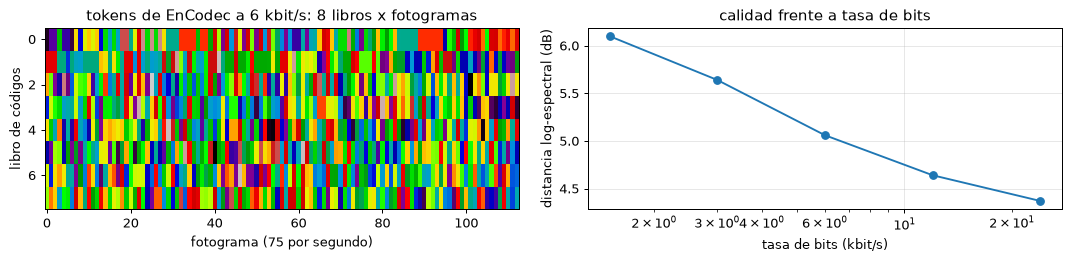

original


EnCodec 1,5 kbit/s (2 libros)


EnCodec 6 kbit/s (8 libros)


[sección 2 (códec): 3 s]


In [4]:
t0 = time.time()
from transformers import EncodecModel
codec = EncodecModel.from_pretrained("facebook/encodec_24khz").eval()
x24 = sps.resample_poly(demo, 3, 2).astype(np.float32)

def lsd(x, y, n_fft=1024, hop=256):
    L = min(len(x), len(y))
    PA, PB = np.abs(stft(x[:L], n_fft, hop)) ** 2, np.abs(stft(y[:L], n_fft, hop)) ** 2
    fl = 1e-6 * PA.max()                                               # ignore everything below -60 dB of the loudest bin
    A, B = np.log10(PA + fl), np.log10(PB + fl)
    return float(np.sqrt(((10 * (A - B)) ** 2).mean(0)).mean())

def si_sdr(ref, est):
    L = min(len(ref), len(est)); ref, est = ref[:L], est[:L]
    a = (est * ref).sum() / (ref ** 2).sum()
    return float(10 * np.log10(((a * ref) ** 2).sum() / (((a * ref) - est) ** 2).sum()))

rows, dec, codes_keep = [], {}, {}
for bw in (1.5, 3.0, 6.0, 12.0, 24.0):
    with torch.no_grad():
        e = codec.encode(torch.tensor(x24)[None, None], bandwidth=bw)
        y = codec.decode(e.audio_codes, e.audio_scales).audio_values[0, 0].numpy()[:len(x24)]
    n_cb, n_fr = e.audio_codes.shape[2], e.audio_codes.shape[3]
    dec[bw], codes_keep[bw] = y, e.audio_codes[0, 0].numpy()
    rows.append({"kbit/s": bw, "libros de códigos": n_cb, "enteros por segundo": n_cb * 75, "compresión frente a PCM de 16 bits": round(24000 * 16 / (bw * 1000)),
                 "LSD (dB)": round(lsd(x24, y), 2), "SI-SDR (dB)": round(si_sdr(x24, y), 1)})
print(pd.DataFrame(rows).to_string(index=False))

fig, ax = plt.subplots(1, 2, figsize=(12, 3))
ax[0].imshow(codes_keep[6.0], aspect="auto", cmap="nipy_spectral", interpolation="nearest")
ax[0].set_title("tokens de EnCodec a 6 kbit/s: 8 libros x fotogramas"); ax[0].set_xlabel("fotograma (75 por segundo)"); ax[0].set_ylabel("libro de códigos")
ax[1].plot([r["kbit/s"] for r in rows], [r["LSD (dB)"] for r in rows], "o-")
ax[1].set_xscale("log"); ax[1].set_xlabel("tasa de bits (kbit/s)"); ax[1].set_ylabel("distancia log-espectral (dB)"); ax[1].set_title("calidad frente a tasa de bits")
ax[1].grid(alpha=0.3); plt.tight_layout(); plt.show()
play(x24, 24000, "original"); play(dec[1.5], 24000, "EnCodec 1,5 kbit/s (2 libros)"); play(dec[6.0], 24000, "EnCodec 6 kbit/s (8 libros)")
lap("sección 2 (códec)", t0)

**Lectura.** Pasar de 1,5 a 24 kbit/s (de 256 a 16 veces más pequeño que el original de 16 bits) baja la distancia log-espectral de 6,1 a 4,4 dB, pero la mayor parte de la mejora llega pronto: de 1,5 a 6 kbit/s se ganan 1,0 dB, de 12 a 24 kbit/s solo 0,3 dB. Los tokens a 6 kbit/s son una cuadrícula de 8 filas por 113 columnas de enteros entre 0 y 1.023; la primera fila (el primer libro de códigos) lleva la estructura gruesa y las siguientes la refinan. El SI-SDR se queda entre -1 y 5 dB incluso a 24 kbit/s: un códec neuronal no reproduce la forma de onda muestra a muestra, reproduce algo que suena parecido, así que una métrica de forma de onda es mal juez para él (y por eso damos también una espectral). El suelo de unos 4 dB es plausible porque el clip es sintético y está lleno de ráfagas de ruido que ningún códec puede predecir exactamente, y el códec se entrenó con voz, música y sonido general, no con nuestro sintetizador. Es un solo clip: usa tus oídos con los tres reproductores y trata la tabla como una ilustración, no como una prueba comparativa.

## 3. Del espectrograma de vuelta a la forma de onda: Griffin-Lim y un vocoder neuronal

La mayoría de los generadores (difusión sobre espectrogramas, modelos acústicos de síntesis de voz) producen una **magnitud** de espectrograma y ninguna fase. Recuperar una forma de onda exige un **vocoder**. Dos maneras:

* **Griffin-Lim** ([Griffin y Lim, 1984](https://doi.org/10.1109/TASSP.1984.1164317)) es un algoritmo iterativo sin aprendizaje: se empieza con una fase aleatoria, se pasa al dominio del tiempo con la STFT inversa, se vuelve con la STFT, se conserva la nueva *fase* pero se restaura la *magnitud* objetivo, y se repite. Cada ronda solo puede reducir la inconsistencia entre la magnitud y una señal real, pero termina en un óptimo local, y el defecto típico es un sonido metálico, "con fase rara". Una variante con **momento** (el Griffin-Lim "rápido") converge más deprisa.
* Un **vocoder neuronal** es una red entrenada para convertir un espectrograma mel en una forma de onda. **HiFi-GAN** ([Kong et al., 2020](https://arxiv.org/abs/2010.05646)) es un generador convolucional entrenado de forma antagónica con discriminadores que miran la forma de onda con varios periodos y escalas, de modo que aprende a producir la fase y el detalle fino que hacen natural el sonido, y es rápido. Usamos el punto de control de HiFi-GAN publicado con SpeechT5 ([Ao et al., 2022](https://arxiv.org/abs/2110.07205)): [ficha del modelo](https://huggingface.co/microsoft/speecht5_hifigan), **licencia MIT**, 16 kHz, 80 bandas mel, entrenado con voz leída (LibriTTS), así que nuestra música sintética queda fuera de su dominio de entrenamiento.

El espectrograma mel tiene menos números que la STFT, así que en la ruta mel primero estimamos una magnitud en frecuencia lineal con unas pocas actualizaciones multiplicativas de mínimos cuadrados no negativos, y después ejecutamos Griffin-Lim sobre ella. Medimos la **distancia log-espectral multirresolución** (diferencia absoluta media de logaritmos naturales de magnitud con tres tamaños de ventana; más baja es mejor), la **distancia log-mel** y, para mostrar por qué aquí no se usa, el SI-SDR de la forma de onda.

Loading weights:   0%|          | 0/158 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 158/158 [00:00<00:00, 49503.25it/s]

fotogramas 94 muestras 24064


HiFi-GAN: 1.50 s de audio en 0.16 s en la CPU (factor de tiempo real 0.11)
                                método  dist. log-espectral multirresolución  dist. log-mel (log10)  SI-SDR (dB)
   Griffin-Lim, magnitud STFT completa                                 0.042                  0.009        -23.3
Griffin-Lim, desde el mel de 80 bandas                                 0.378                  0.046        -20.3
   HiFi-GAN, desde el mel de 80 bandas                                 0.441                  0.184        -29.5


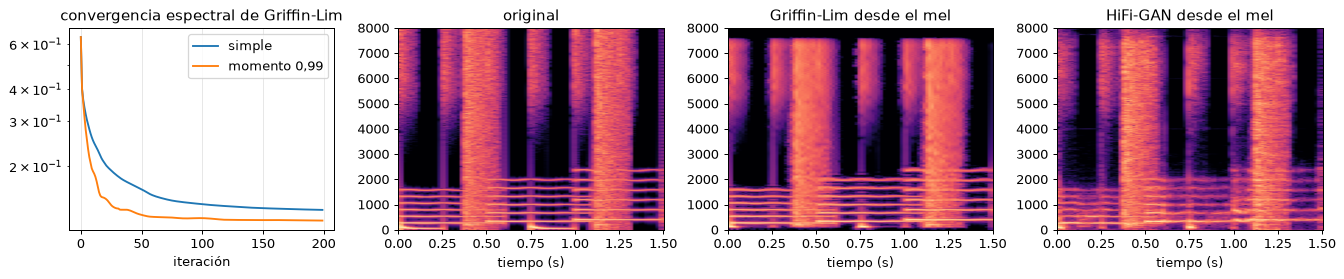

original


Griffin-Lim desde la magnitud STFT completa


Griffin-Lim desde el mel


HiFi-GAN desde el mel


[sección 3 (vocoders): 2 s]


In [5]:
t0 = time.time()
def griffin_lim(S, n_iter=100, n_fft=1024, hop=256, momentum=0.0, seed=0):
    rg = np.random.default_rng(seed)
    X = S * np.exp(2j * np.pi * rg.random(S.shape)); prev = None; hist = []
    for _ in range(n_iter):
        P = stft(istft(X, n_fft, hop), n_fft, hop)
        hist.append(np.linalg.norm(np.abs(P) - S) / np.linalg.norm(S))      # spectral convergence
        Y = P if prev is None else P + momentum * (P - prev)
        prev = P
        X = S * np.exp(1j * np.angle(Y))
    return istft(X, n_fft, hop), hist

def msd(x, y, sizes=(512, 1024, 2048)):
    L = min(len(x), len(y))
    out = []
    for n in sizes:
        A, B = np.abs(stft(x[:L], n, n // 4)), np.abs(stft(y[:L], n, n // 4)); fl = 1e-3 * A.max()      # floor at -60 dB
        out.append(np.abs(np.log(A + fl) - np.log(B + fl)).mean())
    return float(np.mean(out))

from transformers import SpeechT5HifiGan, SpeechT5FeatureExtractor
fe = SpeechT5FeatureExtractor.from_pretrained("microsoft/speecht5_tts")
voc = SpeechT5HifiGan.from_pretrained("microsoft/speecht5_hifigan").eval()
FBV = fe.mel_filters                                                   # (513, 80)

def vocoder_mel(x):                                                    # log10 mel (frames, 80) as the vocoder expects
    return fe(audio_target=x, sampling_rate=16000, return_tensors="np").input_values[0]

mel_o = vocoder_mel(demo)
n_fr = mel_o.shape[0]; L = 256 * n_fr
ref = np.pad(demo, (0, max(0, L - len(demo))))[:L]; S_ref = np.abs(stft(ref, 1024, 256))[:, :n_fr + 1]
print("fotogramas", n_fr, "muestras", L)

# 1) Griffin-Lim from the full STFT magnitude, with and without momentum
_, h_plain = griffin_lim(S_ref, 200, momentum=0.0)
y_gl, h_fast = griffin_lim(S_ref, 200, momentum=0.99)
# 2) Griffin-Lim from the 80-band mel magnitude (NNLS estimate of the linear magnitude)
Mm = (10 ** mel_o).T                                                   # (80, frames), magnitude-mel
Sx = np.maximum(np.linalg.pinv(FBV.T) @ Mm, 1e-6)
for _ in range(60):
    Sx *= (FBV @ Mm) / (FBV @ (FBV.T @ Sx) + 1e-8)
y_glm, _ = griffin_lim(Sx, 100, momentum=0.99)
# 3) neural vocoder from the same mel
with torch.no_grad():
    tv = time.time(); y_hg = voc(torch.tensor(mel_o)[None]).numpy()[0]; t_voc = time.time() - tv
print(f"HiFi-GAN: {len(y_hg) / SR:.2f} s de audio en {t_voc:.2f} s en la CPU (factor de tiempo real {t_voc / (len(y_hg) / SR):.2f})")

def logmel_dist(x):
    m = vocoder_mel(x[:L])[:n_fr]; fl = mel_o.max() - 3                  # log10 scale: ignore below -60 dB
    return float(np.abs(np.maximum(m, fl) - np.maximum(mel_o, fl)).mean())

res = []
for name, y in [("Griffin-Lim, magnitud STFT completa", y_gl), ("Griffin-Lim, desde el mel de 80 bandas", y_glm), ("HiFi-GAN, desde el mel de 80 bandas", y_hg)]:
    res.append({"método": name, "dist. log-espectral multirresolución": round(msd(ref, y), 3), "dist. log-mel (log10)": round(logmel_dist(y), 3), "SI-SDR (dB)": round(si_sdr(ref, y), 1)})
print(pd.DataFrame(res).to_string(index=False))

fig, ax = plt.subplots(1, 4, figsize=(15, 3.2))
ax[0].semilogy(h_plain, label="simple"); ax[0].semilogy(h_fast, label="momento 0,99")
ax[0].set_title("convergencia espectral de Griffin-Lim"); ax[0].set_xlabel("iteración"); ax[0].legend(); ax[0].grid(alpha=0.3)
for a, (nm, y) in zip(ax[1:], [("original", ref), ("Griffin-Lim desde el mel", y_glm), ("HiFi-GAN desde el mel", y_hg)]):
    a.imshow(db(stft(y[:L], 1024, 256)), origin="lower", aspect="auto", extent=[0, L / SR, 0, 8000], vmin=-60, cmap="magma"); a.set_title(nm); a.set_xlabel("tiempo (s)")
plt.tight_layout(); plt.show()
play(ref, SR, "original"); play(y_gl, SR, "Griffin-Lim desde la magnitud STFT completa")
play(y_glm, SR, "Griffin-Lim desde el mel"); play(y_hg, SR, "HiFi-GAN desde el mel")
lap("sección 3 (vocoders)", t0)

**Lectura.** Tres cosas. Primero, Griffin-Lim con la magnitud *completa* de la STFT recupera el sonido casi a la perfección en magnitud (distancia 0,04) y sin embargo su SI-SDR es de -23 dB: la fase que encontró es completamente distinta de la original, y el error de forma de onda no dice nada de cómo suena. Segundo, a partir del mel de 80 bandas, Griffin-Lim puntuó mejor que HiFi-GAN en nuestras medidas espectrales (0,38 frente a 0,44, y 0,05 frente a 0,18 en la distancia log-mel). Eso **no** es evidencia de que Griffin-Lim suene mejor: estas medidas comparan magnitudes, que es exactamente lo que optimiza Griffin-Lim, mientras que HiFi-GAN se entrenó para engañar a discriminadores con formas de onda de sonido natural, con voz leída, y nuestra entrada es música sintética fuera de ese dominio. Tercero, la velocidad: HiFi-GAN produjo 1,5 s de audio en 0,16 s (un factor de tiempo real de 0,11) con una sola pasada, mientras que Griffin-Lim necesita muchas iteraciones de dos transformadas. Compara los cuatro reproductores de oído antes de creer ninguno de los números; un clip y una entrada son una demostración, no una clasificación.

## 4. Dos familias de generadores de audio sobre un conjunto de sonidos de juguete

Hay dos maneras dominantes de generar audio a partir de una representación, y ambas las usan los sistemas de la sección 5:

* **Autoregresiva sobre tokens discretos.** Se convierte el sonido en enteros (tokens de códec), se entrena un modelo de lenguaje para predecir el entero siguiente dada la historia y una **condición** (una clase o un texto), se muestrea token a token y se decodifica. Hereda todo de los modelos de lenguaje (escala, prompts, temperatura de muestreo) y el techo de calidad lo fija el códec.
* **Difusión sobre espectrogramas o latentes.** Se trata el espectrograma mel como una imagen, se entrena un eliminador de ruido exactamente como en el [módulo 05 de Neural Networks 1002](https://neural-networks-1002.academy.forwardforecasting.eu/es/05-modelos-de-difusion/), se muestrea por eliminación iterativa del ruido y después se invierte con un vocoder. También existe la difusión directamente sobre formas de onda: **DiffWave** ([Kong et al., 2021](https://arxiv.org/abs/2009.09761)) es un vocoder de este tipo, y Stable Audio ([Evans et al., 2024](https://arxiv.org/abs/2402.04825)) ejecuta la difusión en el espacio latente de un autoencoder de audio aprendido.

### El conjunto de sonidos de juguete

Cinco tipos de sonido, de 0,512 s cada uno a 16 kHz, con tono, decaimiento, instante de inicio y nivel de ruido aleatorios: **bombo** (kick), **caja** (snare), **hi-hat** (hat), un **tono** estable y un **chirrido** (chirp) ascendente. Representamos cada uno como una imagen log-mel de 32 x 32 (32 bandas mel por 32 fotogramas, ventana 512, salto 256), escalada a [-1, 1]. 1.300 clips entrenan los generadores, 300 clips reservados son la referencia de medición y otros 300 clips reales miden el suelo.

### Cómo medimos los sonidos generados (la idea de la evaluación real)

Entrenamos un pequeño **juez** convolucional con los sonidos reales de entrenamiento para distinguir los cinco tipos. Después, para un conjunto generado, damos: (1) la **precisión de tipo**: el acuerdo del juez con el tipo que se pidió al generador; (2) una **distancia de Fréchet** (FD, Fréchet distance) entre los vectores de 32 características del juez de los sonidos generados y de los reales reservados: se ajusta una gaussiana de media $\mu$ y covarianza $\Sigma$ a cada conjunto y se calcula $\lVert\mu_g-\mu_r\rVert^2+\mathrm{tr}\big(\Sigma_g+\Sigma_r-2(\Sigma_g\Sigma_r)^{1/2}\big)$, donde $g$ significa generado y $r$ real (más baja es mejor; es la receta de la distancia de Fréchet de audio, véase la sección 6); (3) una **distancia espectral al vecino más cercano**: la distancia media (raíz del error cuadrático medio), en la imagen log-mel escalada, de cada sonido generado a su sonido de *entrenamiento* más cercano (muy pequeña significaría copiar el conjunto de entrenamiento, grande significa fuera de distribución). La primera fila de cada tabla da las mismas medidas para un segundo conjunto separado de sonidos reales, como suelo (un conjunto real no está a distancia 0 de otro conjunto real: la distancia de Fréchet de dos muestras finitas siempre es mayor que 0).

entrenamiento (1300, 32, 32) test de referencia (300, 32, 32) segundo conjunto real (300, 32, 32)


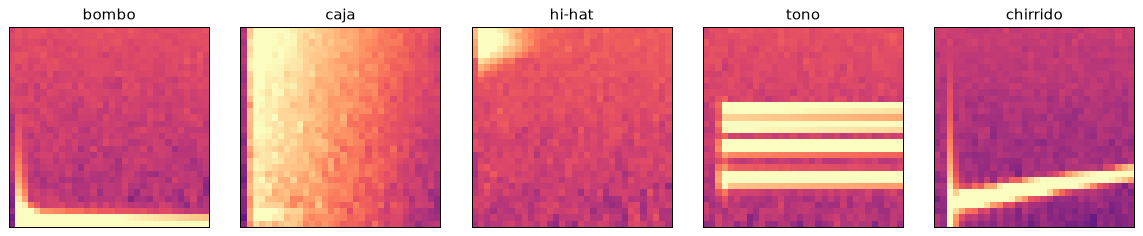

precisión del juez en sonidos reales reservados: 1.0
                                     conjunto  precisión de tipo  distancia de Frechet  distancia al más cercano de entrenamiento
un segundo conjunto de sonidos reales (suelo)                1.0                 61.58                                      0.101
[sección 4 datos y juez: 3 s]


In [6]:
t0 = time.time()
rng = np.random.default_rng(1)
NS, NF, NM, CLASSES = 8192, 32, 32, ["bombo", "caja", "hi-hat", "tono", "chirrido"]
FBT = mel_fb(SR, 512, NM, 0, 8000)

def make_clip(c, rg):
    onset = int(rg.integers(0, 700)); n = NS - onset
    if c == 0:   y = kick(n, rg.uniform(100, 160), rg.uniform(40, 60), rg.uniform(0.08, 0.2))
    elif c == 1: y = snare(n, rg, rg.uniform(150, 260), rg.uniform(0.06, 0.14), rg.uniform(0.5, 1.0))
    elif c == 2: y = hat(n, rg, rg.uniform(0.02, 0.06))
    elif c == 3: y = harmonic(rg.uniform(200, 900), n / SR, n_harm=int(rg.integers(2, 6)), tau=rg.uniform(0.2, 0.6))
    else:
        f_a = rg.uniform(250, 600); y = chirp(n, f_a, f_a * rg.uniform(2.5, 4.5), rg.uniform(0.15, 0.4))
    x = np.zeros(NS); y = y[:n]; x[onset:onset + len(y)] = y
    x = x / (np.abs(x).max() + 1e-9) + rg.standard_normal(NS) * rg.uniform(0.0005, 0.01)
    return x

def logmel_img(x):
    P = np.abs(stft(x, 512, 256))[:, :NF] ** 2
    return np.log10(FBT @ P + 1e-6)                                     # (NM, NF)

per_class = 380
raw, labels = [], []
for c in range(5):
    for _ in range(per_class):
        raw.append(make_clip(c, rng)); labels.append(c)
raw = np.array(raw, dtype=np.float32); labels = np.array(labels)
L_img = np.array([logmel_img(x) for x in raw])
LO, HI = -6.0, 2.0
Xn = (np.clip(L_img, LO, HI) - LO) / (HI - LO) * 2 - 1                  # scaled to [-1, 1]
perm = rng.permutation(len(Xn))
test_idx = np.concatenate([perm[labels[perm] == c][:60] for c in range(5)])            # the reference set for every measurement
test2_idx = np.concatenate([perm[labels[perm] == c][60:120] for c in range(5)])        # a second real set, to measure the floor
mask = np.ones(len(Xn), bool); mask[test_idx] = False; mask[test2_idx] = False
Xtr, ytr, Xte, yte, Xte2, yte2 = Xn[mask], labels[mask], Xn[test_idx], labels[test_idx], Xn[test2_idx], labels[test2_idx]
print("entrenamiento", Xtr.shape, "test de referencia", Xte.shape, "segundo conjunto real", Xte2.shape)

fig, ax = plt.subplots(1, 5, figsize=(13, 2.6))
for c in range(5):
    ax[c].imshow(Xtr[ytr == c][0], origin="lower", cmap="magma", vmin=-1, vmax=1); ax[c].set_title(CLASSES[c]); ax[c].set_xticks([]); ax[c].set_yticks([])
plt.tight_layout(); plt.show()

class Judge(nn.Module):
    def __init__(s):
        super().__init__()
        s.conv = nn.Sequential(nn.Conv2d(1, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2), nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
                               nn.Conv2d(32, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2), nn.Flatten(), nn.Linear(512, 32), nn.ReLU())
        s.head = nn.Linear(32, 5)
    def feats(s, x): return s.conv(x)
    def forward(s, x): return s.head(s.conv(x))

torch.manual_seed(0)
judge = Judge(); opt = torch.optim.Adam(judge.parameters(), 2e-3)
Xt_, yt_ = torch.tensor(Xtr)[:, None].float(), torch.tensor(ytr.astype(np.int64))
for ep in range(12):
    p = torch.randperm(len(Xt_))
    for i in range(0, len(p), 64):
        b = p[i:i + 64]; loss = F.cross_entropy(judge(Xt_[b]), yt_[b]); opt.zero_grad(); loss.backward(); opt.step()
judge.eval()

@torch.no_grad()
def judge_feats(X):
    Xt = torch.tensor(np.asarray(X))[:, None].float()
    return judge.feats(Xt).numpy(), judge(Xt).argmax(1).numpy()

def frechet(a, b):
    mu1, mu2 = a.mean(0), b.mean(0); s1, s2 = np.cov(a, rowvar=False), np.cov(b, rowvar=False)
    tr = np.sqrt(np.clip(np.linalg.eigvals(s1 @ s2).real, 0, None)).sum()
    return float(((mu1 - mu2) ** 2).sum() + np.trace(s1) + np.trace(s2) - 2 * tr)

F_te, pred_te = judge_feats(Xte)
Xtr_flat = torch.tensor(Xtr.reshape(len(Xtr), -1)).float()
def nn_dist(X):
    d = torch.cdist(torch.tensor(np.asarray(X).reshape(len(X), -1)).float(), Xtr_flat) / math.sqrt(NM * NF)
    return float(d.min(1).values.mean())

def score(name, X, asked):
    Fg, pg = judge_feats(X)
    return {"conjunto": name, "precisión de tipo": round(float((pg == asked).mean()), 3), "distancia de Frechet": round(frechet(Fg, F_te), 2), "distancia al más cercano de entrenamiento": round(nn_dist(X), 3)}

print("precisión del juez en sonidos reales reservados:", round(float((pred_te == yte).mean()), 3))
sub2 = np.concatenate([np.where(yte2 == c)[0][:30] for c in range(5)]); sub1 = np.concatenate([np.where(yte == c)[0][:30] for c in range(5)])
score_rows = [score("un segundo conjunto de sonidos reales (suelo)", Xte2[sub2], yte2[sub2])]
print(pd.DataFrame(score_rows).to_string(index=False))
lap("sección 4 datos y juez", t0)

### Familia 1: un códec de un solo libro de códigos y un modelo autoregresivo sobre sus tokens

Construimos el códec más pequeño posible: **cuantización vectorial** con k-means. Cada columna de la imagen (un espectro de 32 bandas, es decir, un fotograma de tiempo) se sustituye por el índice del más cercano de $K = 64$ centroides aprendidos con los fotogramas de entrenamiento. Un sonido pasa a ser **32 enteros**. Un modelo autoregresivo, una **GRU** (gated recurrent unit, unidad recurrente con puertas; véase el [módulo 06 de Neural Networks 1001](https://neural-networks.academy.forwardforecasting.eu/es/06-redes-recurrentes/)) de dos capas, se entrena para predecir el token siguiente dados los anteriores y un **token de clase** puesto al principio (el "prompt"), exactamente como un modelo de lenguaje. El muestreo saca un token cada vez de la distribución predicha. Un códec real añade más libros de códigos (cuantización residual) y un codificador y un decodificador aprendidos; el códec de k-means es la versión de un libro y sin aprendizaje. Su **techo** se mide cuantizando y descuantizando sonidos *reales*.

In [7]:
t0 = time.time()
from sklearn.cluster import KMeans
K = 64
frames_tr = Xtr.transpose(0, 2, 1).reshape(-1, NM)                       # every time frame is one vector
km = KMeans(K, n_init=3, random_state=0).fit(frames_tr)
def tokenise(X): return km.predict(X.transpose(0, 2, 1).reshape(-1, NM)).reshape(len(X), NF)
def detokenise(tok): return km.cluster_centers_[tok].reshape(len(tok), NF, NM).transpose(0, 2, 1)
tok_tr = tokenise(Xtr)
score_rows.append(score("reales reservados a través del códec k-means (techo del AR)", detokenise(tokenise(Xte[sub1])), yte[sub1]))

class ARGRU(nn.Module):
    def __init__(s, K, C=5, h=192):
        super().__init__()
        s.emb = nn.Embedding(K + C, h); s.gru = nn.GRU(h, h, 2, batch_first=True); s.out = nn.Linear(h, K)
    def forward(s, x, h=None):
        o, h = s.gru(s.emb(x), h); return s.out(o), h

torch.manual_seed(0)
ar = ARGRU(K); opt = torch.optim.Adam(ar.parameters(), 3e-3)
inp = torch.tensor(np.concatenate([K + ytr[:, None], tok_tr[:, :-1]], 1).astype(np.int64)); tgt = torch.tensor(tok_tr.astype(np.int64))
ar_loss = []
for ep in range(25):
    p = torch.randperm(len(inp))
    for i in range(0, len(p), 64):
        b = p[i:i + 64]; lo, _ = ar(inp[b]); loss = F.cross_entropy(lo.reshape(-1, K), tgt[b].reshape(-1)); opt.zero_grad(); loss.backward(); opt.step()
    ar_loss.append(loss.item())
print(f"GRU autoregresiva: pérdida final de entrenamiento {ar_loss[-1]:.3f} nats por token (adivinar al azar daría {math.log(K):.2f})")

@torch.no_grad()
def ar_sample(classes, temp=1.0, seed=0):
    g = torch.Generator().manual_seed(seed)
    x = torch.tensor((K + np.asarray(classes)).astype(np.int64))[:, None]; h = None; out = []
    for _ in range(NF):
        lo, h = ar(x, h); pr = F.softmax(lo[:, -1] / temp, -1); x = torch.multinomial(pr, 1, generator=g); out.append(x)
    return torch.cat(out, 1).numpy()

asked = np.repeat(np.arange(5), 30)
X_ar = detokenise(ar_sample(asked))
score_rows.append(score("autoregresivo sobre tokens (GRU, T=1)", X_ar, asked))
print(pd.DataFrame(score_rows).to_string(index=False))
lap("sección 4 AR", t0)

GRU autoregresiva: pérdida final de entrenamiento 0.337 nats por token (adivinar al azar daría 4.16)
                                                   conjunto  precisión de tipo  distancia de Frechet  distancia al más cercano de entrenamiento
              un segundo conjunto de sonidos reales (suelo)              1.000                 61.58                                      0.101
reales reservados a través del códec k-means (techo del AR)              1.000                112.18                                      0.099
                      autoregresivo sobre tokens (GRU, T=1)              0.993                287.99                                      0.098
[sección 4 AR: 28 s]


### Familia 2: un pequeño modelo de difusión sobre la imagen mel

Reutilizamos la receta de eliminación de ruido del módulo 05: se añade ruido a la imagen a lo largo de $T = 100$ pasos con el calendario $\beta_t$ (ruido añadido en el paso $t$), se entrena una U-Net pequeña (una red convolucional que baja a una resolución más gruesa y vuelve a subir con una conexión de salto) para predecir el ruido $\epsilon$ que se añadió, condicionada al paso de difusión y al tipo de sonido, y se muestrea ejecutando la cadena hacia atrás desde ruido puro. La condición se descarta el 10 % de las veces durante el entrenamiento para que la misma red aprenda también el caso no condicionado, lo que permite la **guía sin clasificador** (classifier-free guidance): al muestrear, la predicción de ruido es $(1+w)\,\epsilon_{\text{cond}} - w\,\epsilon_{\text{uncond}}$ con peso de guía $w$, lo que empuja la muestra hacia lo específico del tipo pedido. Damos $w = 0$ y $w = 3$. La red es diminuta (16 canales, 75.000 parámetros) para que entrene en uno o dos minutos en la CPU.

parámetros de la U-Net: 75569


  (100 pasos tardaron 4 s)


entrenamiento de la difusión: pérdida 0.663 -> 0.062 en 85 s


muestrear 150 sonidos con 100 pasos tardó 7 s


                                                   conjunto  precisión de tipo  distancia de Frechet  distancia al más cercano de entrenamiento
              un segundo conjunto de sonidos reales (suelo)              1.000                 61.58                                      0.101
reales reservados a través del códec k-means (techo del AR)              1.000                112.18                                      0.099
                      autoregresivo sobre tokens (GRU, T=1)              0.993                287.99                                      0.098
         difusión sobre la imagen mel (100 pasos, sin guía)              0.860               7702.44                                      0.152
                  difusión con guía sin clasificador, w = 3              0.987                639.55                                      0.197


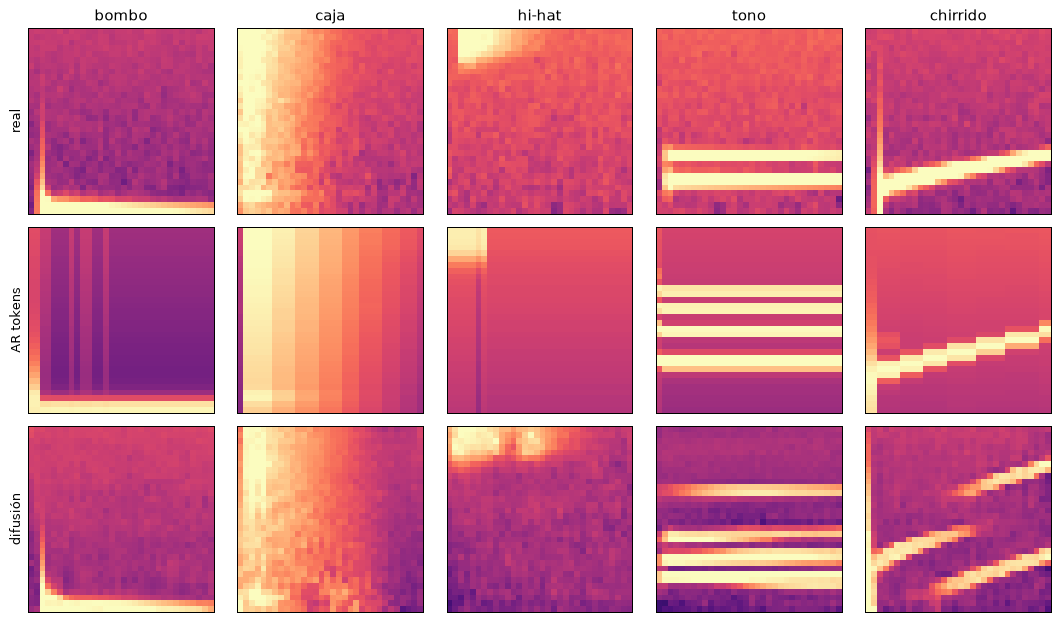

[section 4 diffusion: 107 s]


In [8]:
t0 = time.time()
TD = 100
betas = torch.linspace(1e-4, 0.04, TD); alphas = 1 - betas; abar = torch.cumprod(alphas, 0)

def temb(t, dim=32):
    f = torch.exp(-math.log(10000) * torch.arange(dim // 2) / (dim // 2)); a = t[:, None].float() * f[None]
    return torch.cat([a.sin(), a.cos()], 1)

class Blk(nn.Module):
    def __init__(s, ci, co, ed=64):
        super().__init__()
        s.c1 = nn.Conv2d(ci, co, 3, padding=1); s.c2 = nn.Conv2d(co, co, 3, padding=1)
        s.n1 = nn.GroupNorm(4, ci); s.n2 = nn.GroupNorm(4, co); s.e = nn.Linear(ed, co)
        s.sk = nn.Conv2d(ci, co, 1) if ci != co else nn.Identity()
    def forward(s, x, e):
        h = s.c1(F.silu(s.n1(x))) + s.e(e)[:, :, None, None]
        return s.sk(x) + s.c2(F.silu(s.n2(h)))

class TinyUNet(nn.Module):
    def __init__(s, ch=16, ncls=6):                                          # class 5 means 'no condition'
        super().__init__()
        s.t = nn.Sequential(nn.Linear(32, 64), nn.SiLU(), nn.Linear(64, 64)); s.cls = nn.Embedding(ncls, 64)
        s.inp = nn.Conv2d(1, ch, 3, padding=1); s.d1 = Blk(ch, ch); s.down = nn.Conv2d(ch, 2 * ch, 3, stride=2, padding=1)
        s.d2 = Blk(2 * ch, 2 * ch); s.mid = Blk(2 * ch, 2 * ch); s.up = nn.ConvTranspose2d(2 * ch, ch, 4, stride=2, padding=1)
        s.u1 = Blk(2 * ch, ch); s.out = nn.Conv2d(ch, 1, 3, padding=1)
    def forward(s, x, t, c):
        e = s.t(temb(t)) + s.cls(c)
        h0 = s.d1(s.inp(x), e); h = s.d2(s.down(h0), e); h = s.mid(h, e)
        return s.out(s.u1(torch.cat([s.up(h), h0], 1), e))

torch.manual_seed(0)
unet = TinyUNet(); print("parámetros de la U-Net:", sum(p.numel() for p in unet.parameters()))
opt = torch.optim.Adam(unet.parameters(), 2e-3)
x0_all = torch.tensor(Xtr)[:, None].float(); c_all = torch.tensor(ytr.astype(np.int64))
STEPS_A, BS = 2000, 48
sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=2e-3, total_steps=STEPS_A, pct_start=0.05)
dl = []
tt0 = time.time()
for step in range(STEPS_A):
    b = torch.randint(0, len(x0_all), (BS,)); x0 = x0_all[b]; t = torch.randint(0, TD, (BS,)); eps = torch.randn_like(x0)
    xt = abar[t].sqrt()[:, None, None, None] * x0 + (1 - abar[t]).sqrt()[:, None, None, None] * eps
    cc = c_all[b].clone(); cc[torch.rand(BS) < 0.1] = 5                    # 10 % of the time drop the condition
    loss = F.mse_loss(unet(xt, t, cc), eps); opt.zero_grad(); loss.backward(); opt.step(); sched.step(); dl.append(loss.item())
    if step == 99: print(f"  (100 pasos tardaron {time.time() - tt0:.0f} s)")
print(f"entrenamiento de la difusión: pérdida {np.mean(dl[:50]):.3f} -> {np.mean(dl[-50:]):.3f} en {time.time() - tt0:.0f} s")

@torch.no_grad()
def ddpm_sample(model, classes, w=0.0, seed=0, shape=(1, NM, NF)):
    g = torch.Generator().manual_seed(seed); c = torch.tensor(np.asarray(classes).astype(np.int64)); x = torch.randn((len(c),) + shape, generator=g)
    for i in reversed(range(TD)):
        t = torch.full((len(c),), i); eps = model(x, t, c)
        if w > 0: eps = (1 + w) * eps - w * model(x, t, torch.full_like(c, 5))      # classifier-free guidance
        x0 = (x - (1 - abar[i]).sqrt() * eps) / abar[i].sqrt()
        ab_prev = abar[i - 1] if i > 0 else torch.tensor(1.0)
        mean = (ab_prev.sqrt() * betas[i] / (1 - abar[i])) * x0 + (alphas[i].sqrt() * (1 - ab_prev) / (1 - abar[i])) * x
        x = mean + ((1 - ab_prev) / (1 - abar[i]) * betas[i]).sqrt() * torch.randn(x.shape, generator=g) if i > 0 else mean
    return x[:, 0].numpy()

ts = time.time(); X_df0 = ddpm_sample(unet, asked); print(f"muestrear {len(asked)} sonidos con {TD} pasos tardó {time.time() - ts:.0f} s")
X_df = ddpm_sample(unet, asked, w=3.0)
score_rows.append(score("difusión sobre la imagen mel (100 pasos, sin guía)", X_df0, asked))
score_rows.append(score("difusión con guía sin clasificador, w = 3", X_df, asked))
print(pd.DataFrame(score_rows).to_string(index=False))

fig, ax = plt.subplots(3, 5, figsize=(12, 7))
for c in range(5):
    for r, (nm, X) in enumerate([("real", Xte[yte == c]), ("AR tokens", X_ar[asked == c]), ("difusión", X_df[asked == c])]):
        ax[r, c].imshow(X[1], origin="lower", cmap="magma", vmin=-1, vmax=1); ax[r, c].set_xticks([]); ax[r, c].set_yticks([])
        if c == 0: ax[r, c].set_ylabel(nm)
        if r == 0: ax[r, c].set_title(CLASSES[c])
plt.tight_layout(); plt.show()
lap("section 4 diffusion", t0)

**Lectura.** Las mediciones, sobre 150 sonidos generados por fila (30 por tipo) y un entrenamiento por modelo, están en la tabla de arriba. El suelo es un segundo conjunto de sonidos reales: su distancia de Fréchet es 62, así que una distancia de ese tamaño significa "indistinguible de lo real" con este tamaño de muestra. Fila por fila:

* **Autoregresivo sobre tokens**: el juez reconoce el 99,3 % de los sonidos como el tipo pedido (un error en 150) y la distancia de Fréchet es 288, frente a 112 para sonidos *reales* pasados por el mismo códec de k-means. El códec es el límite principal: el modelo muestrea bien 32 tokens, pero una tabla de 64 espectros no puede representarlo todo.
* **Difusión sin guía**: solo se reconoce el 86 % de los sonidos y la distancia de Fréchet es 7.702: los sonidos tienen las formas correctas (el tambor decae, el chirrido barre) pero la estructura es débil y el nivel global está desajustado (en una comprobación aparte hecha al construir el cuaderno, las imágenes generadas eran más oscuras que las reales), y las características del juez reaccionan con fuerza a eso.
* **Difusión con guía sin clasificador** ($w = 3$): 98,7 % reconocido y una distancia de 640, doce veces menor, con la misma red entrenada. La guía cambia diversidad por fidelidad: la distancia al sonido de entrenamiento más cercano sube de 0,15 a 0,20 (el doble del suelo de 0,10), lo que sugiere ejemplos exagerados, menos naturales, no copias.

Lo que **no** podemos concluir: que una familia sea mejor. La precisión de 0,993 frente a 0,987 es una diferencia de un sonido; las distancias de Fréchet dependen de un juez de 32 características entrenado por nosotros y del tamaño de la muestra (sección 6); la red de difusión tiene 75.000 parámetros y 2.000 pasos de entrenamiento; y cada número es una sola semilla. Lo que el experimento sí muestra son los compromisos característicos: el modelo de tokens está limitado por su códec y es trivialmente rápido de muestrear (milisegundos por sonido), el modelo de difusión necesita cien evaluaciones de la red por muestra y guía para ser utilizable, y una métrica como la precisión puede verse bien mientras una distancia entre distribuciones está lejos del suelo.

### Escuchar las muestras de juguete

Para escuchar, convertimos una imagen log-mel generada otra vez en forma de onda: deshacemos el escalado, pasamos de las 32 bandas mel a una magnitud lineal con el mismo paso de mínimos cuadrados no negativos de antes, y ejecutamos Griffin-Lim. Los sonidos son cortos (0,5 s) y la conversión es tosca, así que espera un carácter áspero, no limpio; lo importante es que el *tipo* de sonido se reconoce.

In [9]:
def image_to_audio(img, n_iter=60):
    P = 10 ** ((np.asarray(img) + 1) / 2 * (HI - LO) + LO)                 # power mel
    Mg = np.sqrt(np.maximum(P - 1e-6, 1e-9))                                # rough magnitude-mel
    Sx = np.maximum(np.linalg.pinv(FBT) @ Mg, 1e-6)
    for _ in range(40):
        Sx *= (FBT.T @ Mg) / (FBT.T @ (FBT @ Sx) + 1e-8)
    y, _ = griffin_lim(Sx, n_iter, n_fft=512, hop=256, momentum=0.99)
    return y

for c in (0, 2, 3):
    play(image_to_audio(Xte[yte == c][1]), SR, f"{CLASSES[c]}: real")
    play(image_to_audio(X_ar[asked == c][1]), SR, f"{CLASSES[c]}: autoregresivo sobre tokens")
    play(image_to_audio(X_df[asked == c][1]), SR, f"{CLASSES[c]}: difusión")

bombo: real


bombo: autoregresivo sobre tokens


bombo: difusión


hi-hat: real


hi-hat: autoregresivo sobre tokens


hi-hat: difusión


tono: real


tono: autoregresivo sobre tokens


tono: difusión


## 5. Un modelo real de texto a música: MusicGen small

MusicGen ([Copet et al., 2023](https://arxiv.org/abs/2306.05284)) es la familia 1 a gran escala: un Transformer autoregresivo sobre los tokens de un códec al estilo EnCodec (32 kHz, cuatro libros de códigos a 50 fotogramas por segundo), condicionado por un prompt de texto codificado con un codificador de texto T5 congelado. Su truco clave es un **patrón de retardo**: los cuatro libros de códigos de un fotograma no se predicen uno tras otro (lo que multiplicaría por cuatro la longitud de la secuencia) sino en paralelo, con el libro $k$ desplazado $k$ pasos, de modo que un paso del Transformer produce un token para cada libro. Ejecutamos el punto de control **small** de 300 millones de parámetros ([ficha del modelo](https://huggingface.co/facebook/musicgen-small), código en [audiocraft](https://github.com/facebookresearch/audiocraft)).

**Licencia, dicha con cuidado:** el código tiene licencia MIT, pero los **pesos del modelo se publican con CC-BY-NC 4.0, no comercial**. Ejecutarlo en un cuaderno de curso está bien; distribuir su salida en un producto comercial no está permitido con estos pesos. El modelo se entrenó con música licenciada (una colección de sonidos de una empresa y dos catálogos de música de archivo, según la ficha del modelo), que es la razón de la restricción. La música se genera a partir de prompts de texto: nadie es copiado a propósito, pero la ficha del modelo también enumera límites (no genera voces cantadas y rinde peor en estilos no occidentales).

Generamos cuatro segundos para tres prompts, con muestreo y guía sin clasificador de 3, y calculamos descriptores toscos (el centroide espectral, una medida de brillo, y la tasa de inicios de nota, hallados como picos del flujo espectral) para comprobar que los prompts no se ignoran. Cada clip cuesta varios segundos en la CPU.

Loading weights:   0%|          | 0/611 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 611/611 [00:00<00:00, 10742.41it/s]

parámetros de MusicGen small (millones): 587


3.9 s de audio por prompt a 32000 Hz; tokens: 200 pasos x 4 libros = 800 enteros; tiempos de generación (s): [11.5, 11.3, 11.3]
                                             prompt  centroide espectral (Hz)  inicios de nota por segundo
                 slow lullaby played on a music box                      2220                          2.0
energetic drum and bass beat with a heavy kick drum                      5954                          6.3
                   solo acoustic guitar folk melody                      1101                          4.3


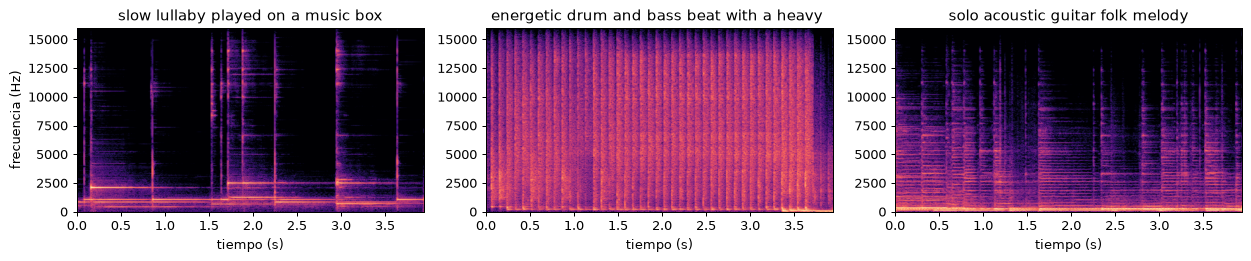

MusicGen small: slow lullaby played on a music box


MusicGen small: energetic drum and bass beat with a heavy kick drum


MusicGen small: solo acoustic guitar folk melody


[sección 5 (MusicGen): 36 s]


In [10]:
t0 = time.time()
from transformers import AutoProcessor, MusicgenForConditionalGeneration
proc = AutoProcessor.from_pretrained("facebook/musicgen-small")
mg = MusicgenForConditionalGeneration.from_pretrained("facebook/musicgen-small").eval()
print("parámetros de MusicGen small (millones):", round(sum(p.numel() for p in mg.parameters()) / 1e6))
SRM = mg.config.audio_encoder.sampling_rate
prompts = ["slow lullaby played on a music box", "energetic drum and bass beat with a heavy kick drum", "solo acoustic guitar folk melody"]
clips, times = [], []
for i, pr in enumerate(prompts):
    torch.manual_seed(i)
    ts = time.time()
    with torch.no_grad():
        a = mg.generate(**proc(text=[pr], padding=True, return_tensors="pt"), do_sample=True, guidance_scale=3.0, max_new_tokens=200)
    times.append(time.time() - ts); clips.append(a[0, 0].numpy())
sec = len(clips[0]) / SRM
print(f"{sec:.1f} s de audio por prompt a {SRM} Hz; tokens: 200 pasos x 4 libros = 800 enteros; tiempos de generación (s): {[round(x, 1) for x in times]}")

def describe(x, sr):
    S = np.abs(stft(x, 1024, 512)); fr = np.fft.rfftfreq(1024, 1 / sr)
    centroid = float((S * fr[:, None]).sum(0).mean() / (S.sum(0).mean() + 1e-9))
    flux = np.maximum(np.diff(np.log(FBM @ S + 1e-4), axis=1), 0).sum(0)
    pk, _ = sps.find_peaks(flux, height=flux.mean() + flux.std(), distance=int(0.1 * sr / 512))
    return centroid, len(pk) / (len(x) / sr)
FBM = mel_fb(SRM, 1024, 40)
rows = []
for pr, x in zip(prompts, clips):
    c, o = describe(x, SRM); rows.append({"prompt": pr, "centroide espectral (Hz)": round(c), "inicios de nota por segundo": round(o, 1)})
print(pd.DataFrame(rows).to_string(index=False))

fig, ax = plt.subplots(1, 3, figsize=(14, 3))
for a, pr, x in zip(ax, prompts, clips):
    a.imshow(db(stft(x, 1024, 256)), origin="lower", aspect="auto", extent=[0, len(x) / SRM, 0, SRM / 2], vmin=-50, cmap="magma"); a.set_title(pr[:42]); a.set_xlabel("tiempo (s)")
ax[0].set_ylabel("frecuencia (Hz)"); plt.tight_layout(); plt.show()
clips16 = [sps.resample_poly(x, 1, 2).astype(np.float32) for x in clips]
for pr, x in zip(prompts, clips16):
    play(x, 16000, "MusicGen small: " + pr)
lap("sección 5 (MusicGen)", t0)

**Lectura.** Generar 3,9 s de música lleva unos 10 s con 2 hilos de CPU (más lento que el tiempo real), con 800 enteros por predecir. Los descriptores toscos se mueven en la dirección esperada: el clip de drum and bass es el más brillante (centroide espectral 5.954 Hz) y tiene más inicios de nota (6,3 por segundo), el de guitarra el más oscuro (1.101 Hz), y la nana de caja de música tiene menos inicios (2,0 por segundo). Con una muestra por prompt y dos descriptores toscos esto es evidencia débil de que los prompts se usan, no una medición de calidad. Escucha: un modelo de 300 millones de parámetros entrenado con música licenciada produce fragmentos cortos plausibles, pero cuatro segundos esconden todo lo difícil (una estructura coherente durante minutos, motivos que se repiten, voces, que este modelo no genera). La licencia no comercial de los pesos forma parte del resultado: decide si puedes usar la salida.

## 6. Evaluar el audio generado

Evaluar un generador es tan difícil como construirlo, porque no hay una única respuesta correcta con la que comparar. La caja de herramientas habitual, por orden de coste:

* **Estadísticas de la salida sin referencia.** Sonoridad, recorte (clipping), silencio, centroide espectral, tasa de inicios (como arriba). Baratas, detectan fallos gruesos, no dicen nada de la calidad.
* **Distancia entre distribuciones: distancia de Fréchet de audio (FAD)** ([Kilgour et al., 2019](https://arxiv.org/abs/1812.08466)). Se calcula el embedding de un conjunto de clips reales y de un conjunto de clips generados con una red de audio preentrenada (el original usó VGGish, un clasificador de audio), se ajusta una gaussiana a cada conjunto y se calcula la distancia de Fréchet de la sección 4. Más baja significa que el conjunto generado se parece más al real *a los ojos de esa red*. Es el hermano de audio del FID (Fréchet inception distance) usado en imágenes. Sus debilidades son bien conocidas: depende de la red de embedding (otra red ordena distinto los sistemas), necesita muchos clips (la estimación está sesgada al alza con conjuntos pequeños) y no ve lo que el embedding ignora.
* **Concordancia texto-audio.** Para texto a audio, un embedding conjunto texto-audio (un modelo CLAP, el primo de audio de CLIP, véase el [módulo 04 de Neural Networks 1002](https://neural-networks-1002.academy.forwardforecasting.eu/es/04-autoencoders-gans-y-autosupervisado/)) puntúa cuánto encaja el clip con el prompt.
* **Pruebas de escucha.** El método de referencia: pedir a personas que puntúen clips (por ejemplo de 1 a 5, nota media de opinión) o que elijan entre dos sistemas. Necesita suficientes oyentes y clips, a ciegas y con orden aleatorio, una referencia oculta y un ancla de baja calidad para detectar evaluadores descuidados; hay que dar intervalos de confianza. Lentas y caras, y la única que mide lo que nos importa.

Abajo, con nuestro juez de juguete, comprobamos dos propiedades de la receta de Fréchet que importan en la práctica: cómo se comporta con **tamaños de muestra pequeños** (comparando dos conjuntos de sonidos *reales*, cuya distancia verdadera es cero) y si **crece cuando los sonidos se degradan** de una manera conocida.

In [11]:
t0 = time.time()
rg = np.random.default_rng(0)
F_tr_all, _ = judge_feats(Xte2)                                  # real sounds the judge never saw
rows = []
for n in (20, 50, 100, 200, 300):
    ds = [frechet(F_tr_all[rg.choice(len(F_tr_all), n, replace=False)], F_te) for _ in range(5)]
    rows.append({"clips por conjunto": n, "FD entre dos conjuntos de sonidos REALES (media de 5 sorteos)": round(float(np.mean(ds)), 2), "std": round(float(np.std(ds)), 2)})
print(pd.DataFrame(rows).to_string(index=False))

rows = []
for sig in (0.0, 0.1, 0.2, 0.4, 0.8):
    Xd = np.clip(Xte + rg.standard_normal(Xte.shape) * sig, -1, 1)
    Fd, pd_ = judge_feats(Xd); rows.append({"ruido añadido a las imágenes de test": sig, "FD al conjunto de test limpio": round(frechet(Fd, F_te), 2), "precisión de tipo": round(float((pd_ == yte).mean()), 3)})
for k in (1, 3):
    Xb = np.stack([sps.convolve2d(x, np.ones((k + 1, k + 1)) / (k + 1) ** 2, mode="same", boundary="symm") for x in Xte])
    Fd, pd_ = judge_feats(Xb); rows.append({"ruido añadido a las imágenes de test": f"desenfoque {k + 1}x{k + 1}", "FD al conjunto de test limpio": round(frechet(Fd, F_te), 2), "precisión de tipo": round(float((pd_ == yte).mean()), 3)})
print(pd.DataFrame(rows).to_string(index=False))
lap("sección 6", t0)

 clips por conjunto  FD entre dos conjuntos de sonidos REALES (media de 5 sorteos)    std
                 20                                                         851.73 474.42
                 50                                                         236.11 110.43
                100                                                         105.48  27.99
                200                                                          53.30  24.43
                300                                                          17.17   0.00


ruido añadido a las imágenes de test  FD al conjunto de test limpio  precisión de tipo
                                 0.0                           0.00              1.000
                                 0.1                          58.99              1.000
                                 0.2                         502.48              1.000
                                 0.4                        3423.27              0.890
                                 0.8                       12515.64              0.507
                      desenfoque 2x2                         150.69              1.000
                      desenfoque 4x4                         838.53              1.000
[sección 6: 0 s]


**Lectura.** La distancia de Fréchet entre dos conjuntos de sonidos *reales*, que debería ser cero, es 852 con 20 clips por conjunto, 236 con 50, 105 con 100, 53 con 200 y 17 con los 300 (la última no tiene dispersión porque usa todos los clips), y la dispersión entre sorteos aleatorios es del mismo orden que el valor en los conjuntos pequeños. Así que una distancia de Fréchet solo es comparable entre sistemas evaluados con la misma red de embedding **y el mismo número de clips**, y los conjuntos de evaluación pequeños son sobre todo ruido. La prueba de degradación muestra la otra cara: un ruido añadido de 0,1 ya mueve la distancia de 0 a 59 mientras la precisión del juez sigue en el 100 %, y solo baja con ruido 0,4 (89 %) y 0,8 (51 %); un desenfoque de 2x2 da 151 y ninguna pérdida de precisión. Una distancia entre distribuciones ve cambios que la precisión de un clasificador no ve, en un espacio que solo es tan significativo como la red que lo define (nuestro juez conoce cinco tipos de sonido y nada de música, la misma razón por la que el FAD basado en VGGish puede discrepar de los oyentes). Da la métrica junto con el embedding, el tamaño de muestra y, siempre que sea posible, una prueba de escucha.

## 7. El vídeo son fotogramas más tiempo

Un vídeo es un tensor con un eje de tiempo: **fotogramas x alto x ancho x canales**. Tres cosas lo hacen más difícil que una imagen:

1. **Tamaño.** Un segundo de vídeo 720p a 24 fotogramas por segundo son 24 imágenes de 0,9 millones de píxeles cada una. Generar píxeles directamente está fuera de alcance, así que los modelos de vídeo trabajan en un espacio **latente** comprimido hecho por un autoencoder que comprime tanto el espacio como el tiempo (como hace el códec con el audio).
2. **Consistencia temporal.** Cada fotograma debe verse bien *y* los fotogramas deben ponerse de acuerdo: los objetos conservan su forma, identidad y color, y se mueven por trayectorias plausibles. Los fallos son visibles: parpadeo, objetos que se derriten, aparecen o desaparecen, fondos que se arrastran. Un modelo que elimina el ruido de cada fotograma de forma independiente produce exactamente esto.
3. **Estructura de largo alcance.** Un plano es una historia: causa y efecto, física, objetos que se van y vuelven.

Arquitectónicamente hay tres maneras de dejar fluir la información por el tiempo:

* **Convoluciones temporales.** Se extiende una convolución 2D a 3D, con un núcleo de tamaño 3 en tiempo, alto y ancho ([Tran et al., 2018](https://arxiv.org/abs/1711.11248)). La versión **(2+1)D** la factoriza en una convolución espacial 2D seguida de una temporal 1D: menos pesos, más no linealidades, más fácil de optimizar. La usamos abajo. El coste es local: para relacionar fotogramas separados 100 fotogramas hay que apilar muchas capas.
* **Atención en el tiempo.** Se alternan atención espacial (los tokens de un fotograma se atienden entre sí) y atención temporal (cada posición espacial se atiende a sí misma a lo largo de los fotogramas). Es la factorización usada por los primeros grandes modelos de difusión de vídeo ([Ho et al., 2022](https://arxiv.org/abs/2204.03458)).
* **Atención sobre parches espacio-temporales.** Se corta el vídeo (latente) en pequeños parches 3D, se aplanan en una única secuencia larga de tokens y un Transformer atiende sobre *todos* (atención espacio-temporal completa). Es lo más flexible y lo más caro, y es el diseño de los sistemas al estilo Sora (sección 10).

Para el juguete necesitamos datos. Generamos clips de **8 fotogramas de 16 por 16 píxeles** que muestran un disco o un cuadrado suavizado que se mueve en línea recta con velocidad aleatoria y rebota en las paredes. Nada más cambia entre fotogramas, así que la única estructura temporal es una trayectoria de velocidad constante, que es exactamente lo que podemos medir.

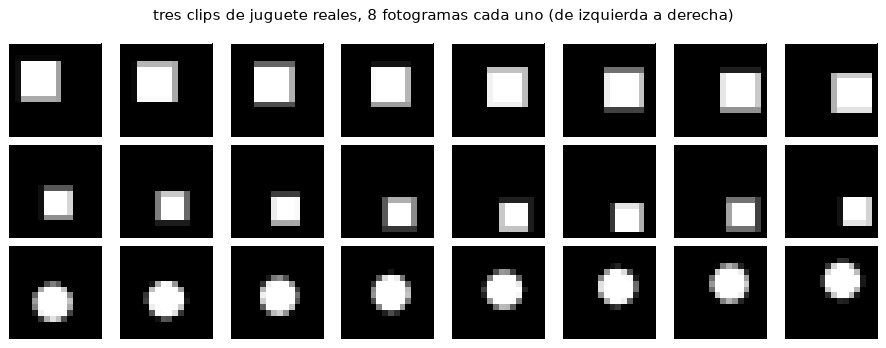

parpadeo de los clips reales (desv. típica del brillo total del objeto en el tiempo, relativa): 0.004
datos: (2000, 8, 16, 16) = clips x fotogramas x alto x ancho


In [12]:
t0 = time.time()
VT, VH = 8, 16
yy, xx = np.mgrid[0:VH, 0:VH].astype(np.float32)

def make_videos(N, seed):
    rg = np.random.default_rng(seed)
    r = rg.uniform(2.2, 3.4, N); shape = rg.integers(0, 2, N)
    pos = np.stack([rg.uniform(4, VH - 4, N), rg.uniform(4, VH - 4, N)], 1)
    ang = rg.uniform(0, 2 * np.pi, N); sp = rg.uniform(0.5, 1.4, N)
    vel = np.stack([np.cos(ang), np.sin(ang)], 1) * sp[:, None]
    vid = np.zeros((N, VT, VH, VH), np.float32)
    for t in range(VT):
        dx, dy = xx[None] - pos[:, 0, None, None], yy[None] - pos[:, 1, None, None]
        d = np.where(shape[:, None, None] == 0, np.sqrt(dx ** 2 + dy ** 2), np.maximum(np.abs(dx), np.abs(dy)))
        vid[:, t] = np.clip(r[:, None, None] + 0.5 - d, 0, 1)
        pos = pos + vel
        for k in range(2):
            lo = pos[:, k] < r + 0.5; hi = pos[:, k] > VH - 1 - r - 0.5
            vel[lo | hi, k] *= -1; pos[:, k] = np.clip(pos[:, k], r + 0.5, VH - 1 - r - 0.5)
    return vid

Vtr, Vte = make_videos(2000, 10), make_videos(200, 11)
def strip(ax_row, clip):
    for t in range(VT):
        ax_row[t].imshow(clip[t], cmap="gray", vmin=0, vmax=1); ax_row[t].axis("off")
fig, ax = plt.subplots(3, VT, figsize=(10, 3.9))
for r in range(3): strip(ax[r], Vtr[r])
plt.suptitle("tres clips de juguete reales, 8 fotogramas cada uno (de izquierda a derecha)"); plt.tight_layout(); plt.show()

# how many numbers, and the flicker measure used below
def mass_flicker(v):
    m = np.clip(v, 0, 1).sum((2, 3)); return float((m.std(1) / (m.mean(1) + 1e-6)).mean())
print("parpadeo de los clips reales (desv. típica del brillo total del objeto en el tiempo, relativa):", round(mass_flicker(Vte), 3))
print("datos:", Vtr.shape, "= clips x fotogramas x alto x ancho")

## 8. Generación de vídeo de juguete: predicción del siguiente fotograma y difusión de vídeo

Dos generadores de juguete.

**Un predictor del siguiente fotograma** (el equivalente en vídeo de la familia autoregresiva): una pequeña red convolucional ve los dos fotogramas anteriores y predice el siguiente, entrenada con error cuadrático medio. Para generar un clip, se le dan los dos primeros fotogramas y se le devuelven sus propias predicciones. Los errores se acumulan, y una pérdida de regresión con varios futuros plausibles produce el promedio de ellos: desenfoque.

**Un modelo de difusión de vídeo**: el eliminador de ruido de la sección 4, extendido al eje del tiempo. Sus bloques son **bloques residuales (2+1)D** (una convolución espacial 3x3 y una convolución temporal de núcleo 3), de modo que cada fotograma puede ver a sus vecinos. Para medir lo que aportan las capas de tiempo, entrenamos un **gemelo con núcleo temporal de tamaño 1**, que no tiene forma de intercambiar información entre fotogramas y por tanto elimina el ruido de 8 imágenes independientes apiladas en un tensor. Ambos se entrenan el mismo número de pasos con los mismos datos, y después se muestrean clips desde ruido puro.

**Cómo medimos la consistencia temporal.** (1) **Parpadeo**: la desviación típica en el tiempo del brillo total del objeto, dividida por su media (clips reales: cerca de 0). (2) **Error de deformación por flujo óptico**, la medida estándar en los artículos de edición de vídeo: se estima el movimiento entre dos fotogramas consecutivos con una red de flujo (RAFT, sección 9), se deforma el fotograma siguiente hacia atrás con ese flujo y se compara con el actual. Si el vídeo es temporalmente coherente, el movimiento explica el cambio y el error es pequeño; si los objetos parpadean, cambian de forma o aparecen de golpe, ningún movimiento explica el cambio y el error es grande. Lo calculamos sobre fotogramas ampliados a 128 x 128 (RAFT lo necesita como mínimo).

In [13]:
t0 = time.time()
from torchvision.models.optical_flow import raft_small, Raft_Small_Weights
raft = raft_small(weights=Raft_Small_Weights.DEFAULT).eval()

def to_rgb(v):                                                          # (N, T, H, W) in [0,1] -> (N, T, 3, 128, 128) in [-1,1]
    N, T = v.shape[:2]
    x = F.interpolate(torch.tensor(np.clip(v, 0, 1)).reshape(N * T, 1, VH, VH).float(), size=128, mode="bilinear", align_corners=False)
    return (x * 2 - 1).repeat(1, 3, 1, 1).reshape(N, T, 3, 128, 128)

@torch.no_grad()
def raft_flow(a, b, bs=96):                                             # a, b: (B, 3, 128, 128) -> flow a to b (B, 2, 128, 128)
    return torch.cat([raft(a[i:i + bs], b[i:i + bs])[-1] for i in range(0, len(a), bs)])

def warp(img, flow):                                                    # sample img at x + flow(x)
    B, _, H, W = img.shape
    gy, gx = torch.meshgrid(torch.arange(H).float(), torch.arange(W).float(), indexing="ij")
    grid = torch.stack([(gx + flow[:, 0]) / (W - 1) * 2 - 1, (gy + flow[:, 1]) / (H - 1) * 2 - 1], -1)
    return F.grid_sample(img, grid, align_corners=True, padding_mode="border")

def warp_error(v):
    x = to_rgb(v); N, T = x.shape[:2]
    a, b = x[:, :-1].reshape(-1, 3, 128, 128), x[:, 1:].reshape(-1, 3, 128, 128)
    fl = raft_flow(a, b)
    err = ((a - warp(b, fl)).abs() / 2).mean((1, 2, 3))                  # back to the [0,1] pixel scale
    return float(err.mean())

class NextFrame(nn.Module):
    def __init__(s, ch=32):
        super().__init__()
        s.net = nn.Sequential(nn.Conv2d(2, ch, 3, padding=1), nn.ReLU(), nn.Conv2d(ch, ch, 3, padding=1), nn.ReLU(), nn.Conv2d(ch, ch, 3, padding=1), nn.ReLU(),
                              nn.Conv2d(ch, ch, 3, padding=1), nn.ReLU(), nn.Conv2d(ch, 1, 3, padding=1))
    def forward(s, x): return s.net(x)

torch.manual_seed(0)
nf = NextFrame(); opt = torch.optim.Adam(nf.parameters(), 2e-3)
V = torch.tensor(Vtr)
tt0 = time.time()
for step in range(1500):
    b = torch.randint(0, len(V), (64,)); t = torch.randint(2, VT, (64,))
    ctx = torch.stack([V[b, t - 2], V[b, t - 1]], 1); tgt = V[b, t][:, None]
    loss = F.mse_loss(nf(ctx), tgt); opt.zero_grad(); loss.backward(); opt.step()
print(f"predictor del siguiente fotograma entrenado en {time.time() - tt0:.0f} s, pérdida final {loss.item():.4f}")

@torch.no_grad()
def rollout(v):
    fr = [torch.tensor(v[:, 0]), torch.tensor(v[:, 1])]
    for t in range(2, VT):
        fr.append(nf(torch.stack(fr[-2:], 1))[:, 0].clamp(0, 1))
    return torch.stack(fr, 1).numpy()

Rte = rollout(Vte)
rows = []
for h in range(2, VT):
    rows.append({"fotograma": h, "horizonte": h - 1, "ECM modelo del siguiente fotograma": float(((Rte[:, h] - Vte[:, h]) ** 2).mean()), "ECM copiar el último fotograma conocido": float(((Vte[:, 1] - Vte[:, h]) ** 2).mean()),
                 "brillo conservado (pred/real)": float(Rte[:, h].sum((1, 2)).mean() / Vte[:, h].sum((1, 2)).mean())})
print(pd.DataFrame(rows).round(4).to_string(index=False))
WE_REAL = warp_error(Vte[:64])
print("proyección del siguiente fotograma: parpadeo", round(mass_flicker(Rte), 3), "| error de deformación", round(warp_error(Rte[:64]), 4), "| error de deformación de clips reales", round(WE_REAL, 4))
lap("sección 8 siguiente fotograma", t0)

predictor del siguiente fotograma entrenado en 14 s, pérdida final 0.0029
 fotograma  horizonte  ECM modelo del siguiente fotograma  ECM copiar el último fotograma conocido  brillo conservado (pred/real)
         2          1                              0.0028                                   0.0234                         1.0164
         3          2                              0.0109                                   0.0569                         1.0287
         4          3                              0.0260                                   0.0843                         1.0454
         5          4                              0.0461                                   0.1070                         1.0696
         6          5                              0.0672                                   0.1246                         1.1074
         7          6                              0.0870                                   0.1357                         1.1469


proyección del siguiente fotograma: parpadeo 0.272 | error de deformación 0.0134 | error de deformación de clips reales 0.0108
[sección 8 siguiente fotograma: 37 s]


**Lectura.** El modelo del siguiente fotograma supera a copiar el último fotograma conocido en todos los horizontes (error cuadrático 0,0028 frente a 0,023 un fotograma por delante), pero la ventaja se reduce al acumularse los errores: 0,087 frente a 0,136 seis fotogramas por delante. El brillo total del fotograma predicho se desvía del 102 % al 115 % del verdadero: el objeto se difumina y deja fantasmas, que es el desenfoque de una pérdida de regresión con un error acumulado. El parpadeo relativo de las proyecciones es 0,28 frente a 0,004 en clips reales, así que la medida basada en el brillo lo detecta, mientras que el error de deformación por flujo óptico (0,0134 frente a 0,0108 en clips reales) casi no: RAFT encuentra un movimiento que explica un objeto difuminado igual de bien. Ninguna métrica temporal sola basta.

capas espacio-temporales (núcleo temporal 3): parámetros 28513, pérdida 0.285 -> 0.035, entrenar 81 s, muestrear 2 s


capas por fotograma (núcleo temporal 1): parámetros 25441, pérdida 0.275 -> 0.035, entrenar 74 s, muestrear 2 s


                                                      clips  parpadeo  error de deformación por flujo óptico
                                       clips de test reales     0.004                                 0.0108
                         proyección del siguiente fotograma     0.283                                 0.0134
      capas espacio-temporales (núcleo temporal 3) difusión     0.457                                 0.0530
           capas por fotograma (núcleo temporal 1) difusión     0.486                                 0.1600
fotogramas de clips reales distintos (sin vínculo temporal)     0.266                                 0.0544


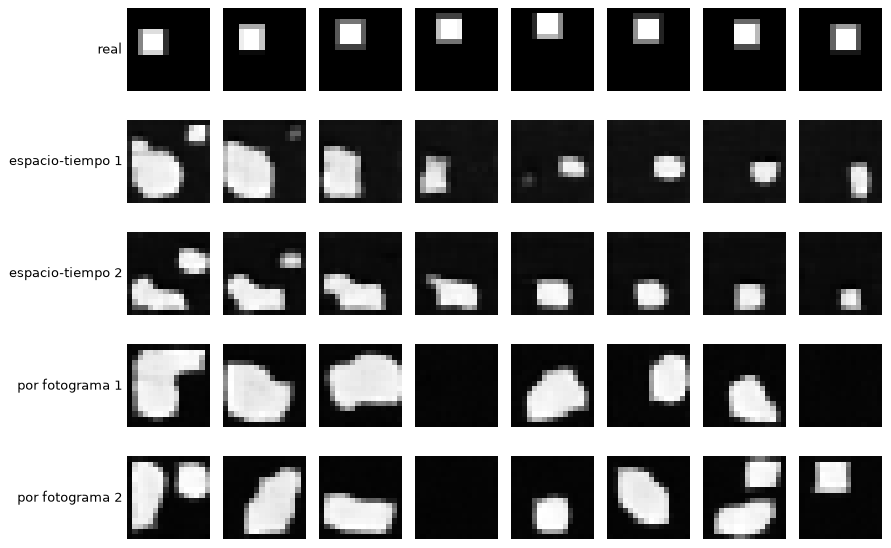

[sección 8 difusión de vídeo: 214 s]


In [14]:
t0 = time.time()
class STBlock(nn.Module):                                               # (2+1)D residual block: spatial 3x3 then temporal conv of size tk
    def __init__(s, ch, tk, ed=64):
        super().__init__()
        s.n1, s.n2 = nn.GroupNorm(4, ch), nn.GroupNorm(4, ch)
        s.s1, s.s2 = nn.Conv3d(ch, ch, (1, 3, 3), padding=(0, 1, 1)), nn.Conv3d(ch, ch, (1, 3, 3), padding=(0, 1, 1))
        s.t1, s.t2 = nn.Conv3d(ch, ch, (tk, 1, 1), padding=(tk // 2, 0, 0)), nn.Conv3d(ch, ch, (tk, 1, 1), padding=(tk // 2, 0, 0))
        s.e = nn.Linear(ed, ch)
    def forward(s, x, e):
        h = s.t1(s.s1(F.silu(s.n1(x)))) + s.e(e)[:, :, None, None, None]
        return x + s.t2(s.s2(F.silu(s.n2(h))))

class VidDenoiser(nn.Module):
    def __init__(s, tk, ch=16, nblk=3):
        super().__init__()
        s.t = nn.Sequential(nn.Linear(32, 64), nn.SiLU(), nn.Linear(64, 64))
        s.inp = nn.Conv3d(1, ch, (1, 3, 3), padding=(0, 1, 1)); s.blks = nn.ModuleList([STBlock(ch, tk) for _ in range(nblk)])
        s.out = nn.Conv3d(ch, 1, (1, 3, 3), padding=(0, 1, 1))
    def forward(s, x, t):
        e = s.t(temb(t)); h = s.inp(x)
        for b in s.blks: h = b(h, e)
        return s.out(h)

TV = 100
vb = torch.linspace(1e-4, 0.04, TV); va = 1 - vb; vab = torch.cumprod(va, 0)
Vt = (torch.tensor(Vtr)[:, None] * 2 - 1)                                # (N, 1, T, H, W) in [-1, 1]

def train_video(tk, steps=2400, seed=0, bs=32):
    torch.manual_seed(seed)
    m = VidDenoiser(tk); o = torch.optim.Adam(m.parameters(), 2e-3); ls = []
    for s_ in range(steps):
        b = torch.randint(0, len(Vt), (bs,)); x0 = Vt[b]; t = torch.randint(0, TV, (bs,)); eps = torch.randn_like(x0)
        xt = vab[t].sqrt()[:, None, None, None, None] * x0 + (1 - vab[t]).sqrt()[:, None, None, None, None] * eps
        loss = F.mse_loss(m(xt, t), eps); o.zero_grad(); loss.backward(); o.step(); ls.append(loss.item())
    return m, ls

@torch.no_grad()
def video_sample(m, n, seed=0):
    g = torch.Generator().manual_seed(seed); x = torch.randn((n, 1, VT, VH, VH), generator=g)
    for i in reversed(range(TV)):
        eps = m(x, torch.full((n,), i)); x0 = ((x - (1 - vab[i]).sqrt() * eps) / vab[i].sqrt()).clamp(-1, 1)
        ap = vab[i - 1] if i > 0 else torch.tensor(1.0)
        mean = (ap.sqrt() * vb[i] / (1 - vab[i])) * x0 + (va[i].sqrt() * (1 - ap) / (1 - vab[i])) * x
        x = mean + ((1 - ap) / (1 - vab[i]) * vb[i]).sqrt() * torch.randn(x.shape, generator=g) if i > 0 else mean
    return ((x[:, 0] + 1) / 2).clamp(0, 1).numpy()

res_v, samples = [], {}
for name, tk in [("capas espacio-temporales (núcleo temporal 3)", 3), ("capas por fotograma (núcleo temporal 1)", 1)]:
    ts = time.time(); m, ls = train_video(tk); tr_s = time.time() - ts
    ts = time.time(); samples[name] = video_sample(m, 64); sa_s = time.time() - ts
    print(f"{name}: parámetros {sum(p.numel() for p in m.parameters())}, pérdida {np.mean(ls[:50]):.3f} -> {np.mean(ls[-50:]):.3f}, entrenar {tr_s:.0f} s, muestrear {sa_s:.0f} s")
res_v.append(("clips de test reales", Vte[:64])); res_v.append(("proyección del siguiente fotograma", Rte[:64]))
for k, v in samples.items(): res_v.append((k + " difusión", v))
rows = []
for nm, v in res_v:
    rows.append({"clips": nm, "parpadeo": round(mass_flicker(v), 3), "error de deformación por flujo óptico": round(warp_error(v), 4)})
indep = np.stack([Vte[(np.arange(64) + 7 * t) % len(Vte), t] for t in range(VT)], 1)         # frame t of each clip comes from a different real clip
rows.append({"clips": "fotogramas de clips reales distintos (sin vínculo temporal)", "parpadeo": round(mass_flicker(indep), 3), "error de deformación por flujo óptico": round(warp_error(indep), 4)})
print(pd.DataFrame(rows).to_string(index=False))

S3, S1 = samples["capas espacio-temporales (núcleo temporal 3)"], samples["capas por fotograma (núcleo temporal 1)"]
film = [("real", Vte[0]), ("espacio-tiempo 1", S3[0]), ("espacio-tiempo 2", S3[1]), ("por fotograma 1", S1[0]), ("por fotograma 2", S1[1])]
fig, ax = plt.subplots(len(film), VT, figsize=(10, 6.4))
for r, (lab, clip) in enumerate(film): strip(ax[r], clip)
for a, (lab, _) in zip(ax[:, 0], film):
    a.axis("on"); a.set_xticks([]); a.set_yticks([]); a.set_ylabel(lab, rotation=0, ha="right", va="center")
    for sp_ in a.spines.values(): sp_.set_visible(False)
plt.tight_layout(); plt.show()
lap("sección 8 difusión de vídeo", t0)

**Lectura.** Ambos eliminadores de ruido alcanzan la misma pérdida de entrenamiento (0,035) pero no los mismos clips. Con capas temporales el error de deformación de las muestras es 0,053; sin ellas es 0,160, tres veces peor: cuando cada fotograma se limpia de forma independiente, los fotogramas consecutivos discrepan y ningún movimiento explica el cambio. Ese es el efecto esperado, medido. Las salvedades son tan grandes como el efecto: las muestras espacio-temporales siguen siendo malas, con un error de deformación tan alto como el de fotogramas reales tomados de clips distintos (0,054, una referencia débil porque RAFT siempre puede explicar dos fotogramas distintos moviendo un disco), y un parpadeo de 0,46 que es mayor incluso que el de esos fotogramas reales sin relación (0,27). El parpadeo de los dos modelos de difusión (0,457 y 0,486) está demasiado cerca para distinguirlos (una semilla, 28.000 parámetros, 2.400 pasos). Lo que el experimento respalda es estrecho: las capas temporales son necesarias para la consistencia (misma pérdida de entrenamiento, error de deformación muy distinto), y la pérdida de entrenamiento sola no revela la calidad temporal. Mira las tiras de fotogramas: los clips reales tienen un objeto limpio, los generados tienen manchas.

## 9. Modelos preentrenados de movimiento: RAFT y un clasificador de vídeo

Dos redes reales preentrenadas, ambas de torchvision y ambas ejecutables en la CPU.

**RAFT** (recurrent all-pairs field transforms, transformaciones recurrentes de campos de todos los pares, [Teed y Deng, 2020](https://arxiv.org/abs/2003.12039)) estima el **flujo óptico**: para cada píxel del fotograma A, el desplazamiento hasta el píxel correspondiente del fotograma B. Construye un volumen de correlación entre todos los pares de píxeles y refina el flujo con una unidad recurrente. Usamos la variante **small** (1 millón de parámetros). El código y los pesos llegan por [torchvision](https://pytorch.org/vision/stable/models/raft.html) (licencia BSD de 3 cláusulas para el código; los pesos se entrenaron con los conjuntos sintéticos FlyingChairs y FlyingThings3D, cuyos propios términos se aplican). Ya lo usamos como regla. Ahora lo usamos como herramienta: la **interpolación de fotogramas**. Dados los fotogramas $t-1$ y $t+1$, se estima el flujo $f$ entre ellos y se construye el fotograma intermedio muestreando cada fotograma medio vector de flujo hacia el centro y promediando. La línea base ingenua es promediar los dos fotogramas, lo que da un fantasma con dos objetos a media intensidad.

**Un clasificador de vídeo** muestra qué capturan las características *espacio-temporales*. Tomamos R(2+1)D-18 ([Tran et al., 2018](https://arxiv.org/abs/1711.11248)), una ResNet con convoluciones (2+1)D preentrenada en Kinetics-400 (400 clases de acciones humanas, [Kay et al., 2017](https://arxiv.org/abs/1705.06950)), de torchvision ([página del modelo](https://pytorch.org/vision/stable/models/generated/torchvision.models.video.r2plus1d_18.html); código BSD de 3 cláusulas; los pesos vienen de entrenar con Kinetics, un conjunto de clips de YouTube: revisa sus términos antes de un uso comercial). Le damos clips sintéticos de un disco brillante que se mueve a la **izquierda, derecha, arriba o abajo** (112 x 112 píxeles, 8 fotogramas), tomamos sus características de 512 dimensiones y entrenamos una sonda lineal (regresión logística, validación cruzada de 5 particiones) para recuperar la dirección. Después repetimos con los **fotogramas de cada clip barajados al azar en el tiempo**: los mismos píxeles, la misma red, pero sin información de movimiento. El azar es el 25 %. Sus etiquetas de Kinetics no significan nada para tales clips; solo usamos las características.

                                      método  PSNR (dB)
                promediar los dos fotogramas       24.3
flujo de RAFT, deformar ambos hasta la mitad       30.9


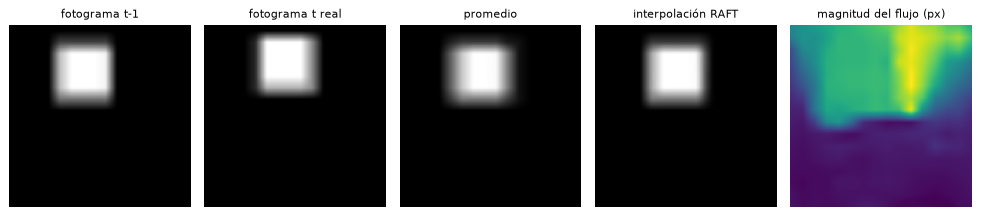

características de 320 clips en 61 s
entrada a la red de vídeo preentrenada  precisión de dirección (5 particiones)   std
            clips en el orden correcto                                   0.981 0.025
los mismos clips, fotogramas barajados                                   0.544 0.032
[sección 9: 76 s]


In [15]:
t0 = time.time()
# --- frame interpolation with RAFT on the held-out toy clips ---
x = to_rgb(Vte[:100])                                                    # (100, 8, 3, 128, 128) in [-1, 1]
mids = torch.arange(1, VT - 1)
a = x[:, mids - 1].reshape(-1, 3, 128, 128); b = x[:, mids + 1].reshape(-1, 3, 128, 128); truth = x[:, mids].reshape(-1, 3, 128, 128)
fl = raft_flow(a, b)
flow_mid = 0.5 * (warp(a, -0.5 * fl) + warp(b, 0.5 * fl))
avg_mid = 0.5 * (a + b)
psnr = lambda p, q: float((10 * torch.log10(4.0 / ((p - q) ** 2).mean((1, 2, 3)))).mean())            # signal range is 2 (from -1 to 1)
rows = [{"método": "promediar los dos fotogramas", "PSNR (dB)": round(psnr(avg_mid, truth), 1)}, {"método": "flujo de RAFT, deformar ambos hasta la mitad", "PSNR (dB)": round(psnr(flow_mid, truth), 1)}]
print(pd.DataFrame(rows).to_string(index=False))
fig, ax = plt.subplots(1, 5, figsize=(11, 2.5))
k = 3
for a_, im_, nm in zip(ax, [a[k], truth[k], avg_mid[k], flow_mid[k], fl[k].norm(dim=0)], ["fotograma t-1", "fotograma t real", "promedio", "interpolación RAFT", "magnitud del flujo (px)"]):
    a_.imshow((im_[0] + 1) / 2 if im_.dim() == 3 else im_, cmap="gray" if im_.dim() == 3 else "viridis"); a_.set_title(nm, fontsize=9); a_.axis("off")
plt.tight_layout(); plt.show()

# --- a pre-trained video classifier as a feature extractor ---
from torchvision.models.video import r2plus1d_18, R2Plus1D_18_Weights
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
wv = R2Plus1D_18_Weights.DEFAULT
vid = r2plus1d_18(weights=wv).eval()
MEAN, STD = torch.tensor([0.43216, 0.394666, 0.37645]).view(1, 3, 1, 1, 1), torch.tensor([0.22803, 0.22145, 0.216989]).view(1, 3, 1, 1, 1)
DIRS = {"right": (1, 0), "left": (-1, 0), "down": (0, 1), "up": (0, -1)}
def move_clips(n_per, seed, H=112, T=8):
    rg = np.random.default_rng(seed); out, lab = [], []
    gy, gx = np.mgrid[0:H, 0:H].astype(np.float32)
    for ci, (nm, (dx, dy)) in enumerate(DIRS.items()):
        for _ in range(n_per):
            p = np.array([rg.uniform(35, 77), rg.uniform(35, 77)]); r = rg.uniform(9, 14); sp = rg.uniform(5, 7)
            bg = rg.uniform(0.0, 0.25); fr = []
            for t in range(T):
                c = p + np.array([dx, dy]) * sp * (t - T / 2)
                fr.append(np.clip(bg + (1 - bg) * np.clip(r + 0.5 - np.sqrt((gx - c[0]) ** 2 + (gy - c[1]) ** 2), 0, 1), 0, 1))
            out.append(np.stack(fr)); lab.append(ci)
    return np.array(out, dtype=np.float32), np.array(lab)
Vm, ym = move_clips(40, 5)
@torch.no_grad()
def r21d_feats(v, bs=16):
    f = []
    head, vid.fc = vid.fc, nn.Identity()
    for i in range(0, len(v), bs):
        x = torch.tensor(v[i:i + bs])[:, None].repeat(1, 3, 1, 1, 1)
        f.append(vid((x - MEAN) / STD))
    vid.fc = head
    return torch.cat(f).numpy()
ts = time.time()
Vsh = np.stack([c[np.random.default_rng(i).permutation(8)] for i, c in enumerate(Vm)])
F_ok = r21d_feats(Vm); F_sh = r21d_feats(Vsh)
print(f"características de {2 * len(Vm)} clips en {time.time() - ts:.0f} s")
probe = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000, C=0.5))
acc_ok = cross_val_score(probe, F_ok, ym, cv=5); acc_sh = cross_val_score(probe, F_sh, ym, cv=5)
print(pd.DataFrame([{"entrada a la red de vídeo preentrenada": "clips en el orden correcto", "precisión de dirección (5 particiones)": round(acc_ok.mean(), 3), "std": round(acc_ok.std(), 3)},
                    {"entrada a la red de vídeo preentrenada": "los mismos clips, fotogramas barajados", "precisión de dirección (5 particiones)": round(acc_sh.mean(), 3), "std": round(acc_sh.std(), 3)}]).to_string(index=False))
lap("sección 9", t0)

**Lectura.** La interpolación de fotogramas con RAFT sube el PSNR (peak signal-to-noise ratio, relación señal-ruido de pico, más alto es mejor) del fotograma intermedio de 24,3 dB (promediar, el fantasma) a 30,9 dB en clips de juguete reservados, una ganancia de 6,6 dB. La escena es el mejor caso para una red de flujo (un objeto limpio, sin oclusión, sin desenfoque de movimiento, una red entrenada con conjuntos de flujo sintéticos), así que el vídeo real dará una ganancia menor. La sonda muestra lo que contienen las características espacio-temporales: el orden correcto da un 98,1 % de precisión en la dirección (desviación típica del 2,5 % entre las cinco particiones) frente al 54,4 % (3,2 %) con fotogramas barajados. El azar es el 25 %, pero barajar conserva el **eje** del movimiento (posiciones repartidas en horizontal o en vertical) y destruye solo el **sentido**, así que alrededor del 50 % es el valor esperado de un modelo que conoce el eje y adivina el sentido, que es lo que vemos. 160 clips y una sonda lineal: una demostración del principio, no una prueba comparativa de la red.

## 10. Texto a vídeo moderno: Transformers de difusión sobre parches latentes espacio-temporales

La descripción pública de la familia Sora ([Brooks et al., 2024](https://openai.com/index/video-generation-models-as-world-simulators/)) y de los sistemas abiertos que la siguieron comparten una receta, armada con piezas que ya conoces:

1. **Un autoencoder de vídeo** (módulo 04) comprime el vídeo en espacio *y* tiempo en un vídeo **latente**: por ejemplo 8 veces más pequeño en alto y ancho y 4 veces en tiempo. Un clip de 5 segundos a 24 fps y 720p de 120 fotogramas se convierte en un latente de 30 x 90 x 160.
2. **Parches espacio-temporales.** El vídeo latente se corta en pequeños bloques 3D (parches), cada uno aplanado y proyectado a un vector: un **token**. Como un token es solo un parche, un mismo modelo puede entrenar con vídeos de cualquier duración, resolución y relación de aspecto (solo cambia el número de tokens), que es el principal argumento práctico del informe.
3. **Un Transformer de difusión** (DiT, [Peebles y Xie, 2023](https://arxiv.org/abs/2212.09748)) es el eliminador de ruido: en lugar de una U-Net es una pila de bloques Transformer sobre los tokens de parche. El **paso de difusión** y el **embedding de texto** entran por las capas de normalización (normalización de capa adaptativa) y por atención cruzada a los tokens del prompt (el prompt lo codifica un modelo de lenguaje grande o un codificador de texto; los pies de imagen largos y descriptivos, a menudo escritos por otro modelo, mejoran el seguimiento del prompt).
4. **Entrenamiento y muestreo** son la receta de difusión del módulo 05 (o su prima, el flow matching), ejecutada en el espacio latente, con guía sin clasificador. El latente de salida pasa por el decodificador de vídeo.
5. **Condicionamiento más allá del texto.** Si se dan fotogramas o latentes de un vídeo existente como tokens extra, la misma red hace imagen a vídeo, extensión hacia delante o hacia atrás, o edición.

El diagrama de abajo lo dibuja, y la tabla que sigue cuenta por qué el diseño es caro: la atención completa sobre $n$ tokens cuesta memoria y tiempo proporcionales a $n^2$.

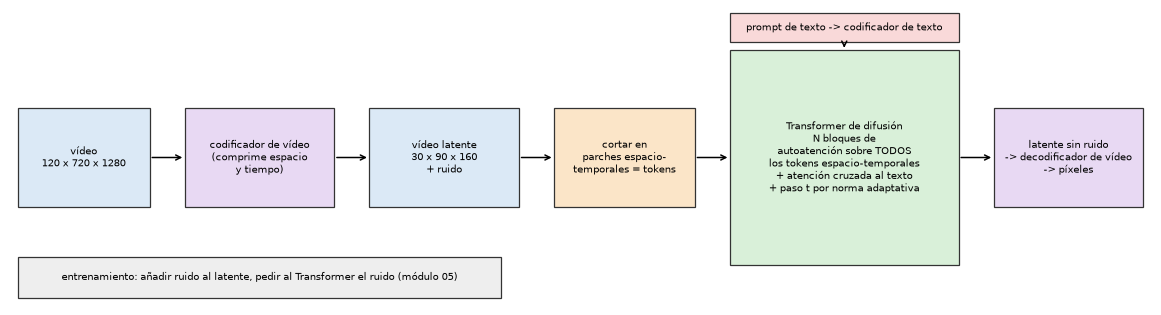

                     clip  píxeles (millones)  tokens  atención completa n^2 (miles de millones)  factorizada: espacio y luego tiempo (miles de millones)
   2 s, 24 fps, 256 x 256                   3    3072                                       0.01                                                    0.001
   5 s, 24 fps, 480 x 854                  49   47700                                       2.28                                                    0.077
  5 s, 24 fps, 720 x 1280                 111  108000                                      11.66                                                    0.392
20 s, 24 fps, 1080 x 1920                 995  964800                                     930.84                                                    7.873
en 720p, un token representa 3072 valores de color en bruto (4 fotogramas x 16 x 16 píxeles x 3 canales)


In [16]:
fig, ax = plt.subplots(figsize=(13, 3.6)); ax.axis("off"); ax.set_xlim(0, 13); ax.set_ylim(0, 3.6)
def box(x, y, w, h, txt, fc):
    ax.add_patch(plt.Rectangle((x, y), w, h, fc=fc, ec="#333", lw=1)); ax.text(x + w / 2, y + h / 2, txt, ha="center", va="center", fontsize=8)
def arrow(x0, y0, x1, y1): ax.annotate("", xy=(x1, y1), xytext=(x0, y0), arrowprops=dict(arrowstyle="->", lw=1.2))
box(0.1, 1.2, 1.5, 1.2, "vídeo\n120 x 720 x 1280", "#dbe9f6"); arrow(1.6, 1.8, 2.0, 1.8)
box(2.0, 1.2, 1.7, 1.2, "codificador de vídeo\n(comprime espacio\ny tiempo)", "#e8d9f3"); arrow(3.7, 1.8, 4.1, 1.8)
box(4.1, 1.2, 1.7, 1.2, "vídeo latente\n30 x 90 x 160\n+ ruido", "#dbe9f6"); arrow(5.8, 1.8, 6.2, 1.8)
box(6.2, 1.2, 1.6, 1.2, "cortar en\nparches espacio-\ntemporales = tokens", "#fbe5c8"); arrow(7.8, 1.8, 8.2, 1.8)
box(8.2, 0.5, 2.6, 2.6, "Transformer de difusión\nN bloques de\nautoatención sobre TODOS\nlos tokens espacio-temporales\n+ atención cruzada al texto\n+ paso t por norma adaptativa", "#d9f0d9"); arrow(10.8, 1.8, 11.2, 1.8)
box(11.2, 1.2, 1.7, 1.2, "latente sin ruido\n-> decodificador de vídeo\n-> píxeles", "#e8d9f3")
box(8.2, 3.2, 2.6, 0.35, "prompt de texto -> codificador de texto", "#f9d9d9"); arrow(9.5, 3.2, 9.5, 3.1)
box(0.1, 0.1, 5.5, 0.5, "entrenamiento: añadir ruido al latente, pedir al Transformer el ruido (módulo 05)", "#eeeeee")
plt.tight_layout(); plt.show()

def n_tokens(frames, h, w, ct=4, cs=8, p=2): return (frames // ct) * (h // cs // p) * (w // cs // p)
rows = []
for nm, fr, h, w in [("2 s, 24 fps, 256 x 256", 48, 256, 256), ("5 s, 24 fps, 480 x 854", 120, 480, 854), ("5 s, 24 fps, 720 x 1280", 120, 720, 1280), ("20 s, 24 fps, 1080 x 1920", 480, 1080, 1920)]:
    n = n_tokens(fr, h, w); ns = (h // 16) * (w // 16); nt = fr // 4
    rows.append({"clip": nm, "píxeles (millones)": round(fr * h * w / 1e6), "tokens": n, "atención completa n^2 (miles de millones)": round(n ** 2 / 1e9, 2),
                 "factorizada: espacio y luego tiempo (miles de millones)": round((nt * ns ** 2 + ns * nt ** 2) / 1e9, 3)})
print(pd.DataFrame(rows).to_string(index=False))
print("en 720p, un token representa", round(120 * 720 * 1280 * 3 / n_tokens(120, 720, 1280)), "valores de color en bruto (4 fotogramas x 16 x 16 píxeles x 3 canales)")

**Lectura.** Los números explican la arquitectura. Un clip de 5 segundos en 720p se convierte en 108.000 tokens, así que la atención completa tiene 11.700 millones de puntuaciones por pares por cabeza y capa, y un clip de 20 segundos en 1080p tiene 965.000 tokens y 931.000 millones: el crecimiento cuadrático es la restricción central. Atender primero dentro de cada fotograma y después a lo largo del tiempo cuesta 390 millones para el clip de 720p, 30 veces menos, que es la razón por la que los primeros modelos de difusión de vídeo factorizaron la atención, y por la que los sistemas que usan atención completa necesitan mucha compresión, núcleos eficientes y muchos aceleradores. Los factores de compresión usados aquí (8 veces en espacio, 4 en tiempo, parches de 2 por 2) son típicos de los sistemas abiertos y **supuestos de este cuaderno**: el informe de Sora no publica sus números exactos.

## 11. Procedencia, marcas de agua y seguridad

Las voces y el vídeo sintéticos realistas son útiles (doblaje, accesibilidad, restaurar una voz perdida por enfermedad, previsualización de cine) y peligrosos a la vez. Los riesgos que debes saber nombrar:

* **Suplantación y fraude.** Unos pocos segundos de una voz real bastan para que un sistema de clonación de voz hable con ella (véase el módulo 07 de Neural Networks 1002); están documentadas las estafas telefónicas con voces clonadas de familiares o directivos. El vídeo sintético de una persona real diciendo o haciendo algo que nunca hizo (un **deepfake**) se usa para fraude, acoso, imágenes íntimas no consentidas y desinformación política.
* **Consentimiento e imagen.** Usar la voz o el rostro de una persona sin su consentimiento es un daño aunque nadie sea engañado. Muchas jurisdicciones dan a las personas derechos sobre su imagen; los modelos y servicios exigen cada vez más prueba de consentimiento para clonar voces.
* **Derechos de autor y datos de entrenamiento.** La música y el cine son obras muy protegidas. Los modelos entrenados con datos licenciados (como MusicGen) difieren legal y éticamente de los entrenados con datos rastreados de la web, y **los pesos de un modelo pueden llevar licencias no comerciales que acompañan a la salida hasta tu producto**. Si la salida de un modelo puede reproducir material de entrenamiento (memorización) es un problema de medición abierto.
* **El dividendo del mentiroso.** Cuando todo se puede falsificar, las grabaciones reales se pueden descartar como falsas.

Las contramedidas técnicas tienen todas límites:

* **Metadatos de procedencia.** C2PA ([Coalition for Content Provenance and Authenticity](https://c2pa.org/)) adjunta a un archivo un historial firmado criptográficamente ("Content Credentials"). Prueba de dónde viene un archivo cuando está intacto y es honesto, y no dice nada una vez eliminados los metadatos (una captura de pantalla, una recodificación).
* **Marcas de agua dentro de la señal.** Un patrón imperceptible añadido al audio o a los píxeles que un detector pueda encontrar después y que debería sobrevivir a la compresión, el ruido y la edición. Las marcas de agua de audio aprendidas, como AudioSeal ([San Roman et al., 2024](https://arxiv.org/abs/2401.17264), [código](https://github.com/facebookresearch/audioseal)), localizan segmentos marcados a nivel de muestra; [SynthID](https://deepmind.google/models/synthid/) de Google DeepMind lo hace para imágenes, audio, vídeo y texto ([Dathathri et al., 2024](https://doi.org/10.1038/s41586-024-08025-4) para el texto). Las marcas de agua solo ayudan cuando el *generador* las aplica, así que los modelos abiertos y los actores maliciosos escapan, y un atacante decidido a menudo puede quitarlas o falsificarlas.
* **Detectores** que clasifican "real frente a sintético" generalizan mal a generadores nuevos y están en una carrera armamentista con ellos.
* **Normas.** La Ley de IA de la UE pide a proveedores y desplegadores que marquen el contenido de audio, imagen y vídeo sintético y que revelen los deepfakes ([artículo 50](https://artificialintelligenceact.eu/article/50/)). Véase también el [módulo 12 de Neural Networks 1002](https://neural-networks-1002.academy.forwardforecasting.eu/es/12-ia-responsable/) sobre IA responsable.

Para sentir qué es una marca de agua, construimos la más simple, una marca de agua de **espectro ensanchado**: se añade al audio un ruido pseudoaleatorio secreto muy bajo (la clave es su semilla, limitado en banda por debajo de 3,5 kHz), y se detecta por **correlación** del audio con el ruido secreto: si la marca está, la correlación, expresada en desviaciones típicas de lo que da el azar (una puntuación $z$), es grande; con una clave equivocada es alrededor de cero. La probamos con un clip de MusicGen de 4 segundos frente a algunas ediciones comunes. Es un juguete: una marca de agua aprendida como AudioSeal es mucho más robusta y se puede localizar.

In [17]:
t0 = time.time()
x = clips16[0].astype(np.float64); x = x / np.abs(x).max(); N = len(x)
BP = sps.butter(6, 3500, "lowpass", fs=16000, output="sos")
def key_noise(key):
    w = sps.sosfilt(BP, np.random.default_rng(key).standard_normal(N)); return w / w.std()
def embed(x, key, snr_db=20):
    return x + key_noise(key) * x.std() * 10 ** (-snr_db / 20)
def zs(y, key):
    w = key_noise(key); c = (y * w).sum() / (np.linalg.norm(y) * np.linalg.norm(w)); return float(c * np.sqrt(N))
KEY = 1234
y = embed(x, KEY, 20)
print("nivel de la marca: relación señal-marca 20 dB; la diferencia al oído es un siseo tenue")
edits = {
    "sin edición": lambda s: s,
    "ruido añadido (10 dB de SNR)": lambda s: s + np.random.default_rng(7).standard_normal(N) * s.std() * 10 ** (-10 / 20),
    "remuestreo 16 -> 8 -> 16 kHz": lambda s: sps.resample_poly(sps.resample_poly(s, 1, 2), 2, 1)[:N],
    "cuantización de 8 bits": lambda s: np.round(s / np.abs(s).max() * 127) / 127 * np.abs(s).max(),
    "recortar los primeros 0,5 s": lambda s: np.concatenate([s[8000:], np.zeros(8000)]),
    "desplazar 3 muestras": lambda s: np.roll(s, 3),
}
wrong = [zs(y, k) for k in range(1, 201)]
rows = []
for nm, f in edits.items():
    e = f(y); rows.append({"edición aplicada al clip con marca": nm, "puntuación z, clave correcta": round(zs(e, KEY), 1), "puntuación z, clip sin marca": round(zs(f(x), KEY), 1)})
print(pd.DataFrame(rows).to_string(index=False))
print(f"200 claves equivocadas sobre el clip con marca: puntuaciones z media {np.mean(wrong):.2f}, desv. típica {np.std(wrong):.2f}, máximo {np.max(wrong):.2f} (la mayor puntuación con clave equivocada es el nivel nulo; el umbral de detección se fija por encima, en 8)")
play(x, 16000, "clip sin marca de agua"); play(y, 16000, "clip con la marca de agua (20 dB por debajo de la música)")
lap("sección 11", t0)

nivel de la marca: relación señal-marca 20 dB; la diferencia al oído es un siseo tenue


edición aplicada al clip con marca  puntuación z, clave correcta  puntuación z, clip sin marca
                       sin edición                          25.3                           0.4
      ruido añadido (10 dB de SNR)                          24.1                           0.2
      remuestreo 16 -> 8 -> 16 kHz                          25.0                           0.4
            cuantización de 8 bits                          25.3                           0.4
       recortar los primeros 0,5 s                          -0.6                          -0.8
              desplazar 3 muestras                          -3.9                           0.8
200 claves equivocadas sobre el clip con marca: puntuaciones z media -0.11, desv. típica 1.62, máximo 4.28 (la mayor puntuación con clave equivocada es el nivel nulo; el umbral de detección se fija por encima, en 8)
clip sin marca de agua


clip con la marca de agua (20 dB por debajo de la música)


[sección 11: 0 s]


**Lectura.** Con la clave correcta el detector da una puntuación z de 25 en el clip con marca, de 24 a 25 tras ruido a 10 dB, remuestreo por 8 kHz y cuantización de 8 bits, y de 0,2 a 0,4 en el clip sin marca; 200 claves equivocadas dan puntuaciones con media -0,1 y desviación típica 1,6 (mayor que 1 porque la música no es ruido blanco), con un máximo de 4,3, así que un umbral de 8 las separa. Falla por completo cuando el clip se recorta o se desplaza solo 3 muestras (z de -0,6 y -3,9): la correlación necesita el audio y la clave alineados, y los sistemas reales buscan entre desplazamientos o usan un detector aprendido que trabaja fotograma a fotograma. Sobrevive al paso-bajo del remuestreo solo porque pusimos la marca por debajo de 3,5 kHz por diseño: un paso-bajo de 2 kHz borraría parte de ella, y cualquiera que conozca el método puede restarla o falsificarla. Por eso las marcas de agua reales se aprenden junto con los ataques, y por eso ninguna es una garantía.

## 12. Ideas clave, ejercicios, referencias

**Ideas clave**

* El audio y el vídeo se generan mediante **representaciones compactas**: espectrogramas, tokens discretos de códec, latentes espacio-temporales. La señal en bruto es demasiado larga. La representación fija el techo de calidad, y el generador (autoregresivo o de difusión) fija el coste y el control.
* La **STFT** tiene un compromiso tiempo-frecuencia (medido arriba), el **espectrograma mel** descarta la fase y un **vocoder** (Griffin-Lim, o uno neuronal como HiFi-GAN) tiene que inventarla de nuevo; el neuronal lo hace más rápido y de forma más natural, al precio de un dominio de entrenamiento.
* Un **códec neuronal** convierte el audio en una cuadrícula de enteros a una tasa de bits medible, de modo que la generación de audio se vuelve modelado de lenguaje (MusicGen) y la calidad se degrada suavemente al quitar libros de códigos.
* **Autoregresivo sobre tokens** y **difusión sobre espectrogramas** funcionan ambos en un juguete; lo que gana o pierde cada uno está en las tablas, no en eslóganes, y con pocas ejecuciones las diferencias deben leerse con su ruido.
* **La evaluación es lo difícil.** Las distancias de Fréchet dependen de la red de embedding y del tamaño de muestra; las pruebas de escucha siguen siendo la referencia. Di lo que una métrica no puede ver.
* **Vídeo = fotogramas + tiempo.** Sin un mecanismo que intercambie información entre fotogramas, los clips generados parpadean; las convoluciones temporales, la atención temporal o la atención espacio-temporal completa son las tres respuestas, con un coste creciente. Los sistemas al estilo Sora convierten en tokens un vídeo latente comprimido en parches espacio-temporales y le eliminan el ruido con un Transformer.
* Nuestros juguetes de vídeo son ilustrativos: 16 x 16 píxeles, un objeto, velocidad constante. Muestran que las mediciones (parpadeo, error de deformación) detectan la falta de capas temporales, no que este modelo pudiera generar vídeo natural.
* **Procedencia y seguridad** forman parte de la ingeniería: licencias de pesos, consentimiento, marcas de agua y metadatos (cada uno con límites conocidos) y normas de transparencia.

**Ejercicios**

1. En la sección 2, repite la tabla del códec con un clip de sonido parecido a la voz (por ejemplo una nota con vibrato y modulación rápida de amplitud) y con ruido blanco. ¿Qué señal es la más barata de comprimir y cuál la más difícil para EnCodec, y por qué?
2. Sustituye la ventana de Hann de `stft` por una rectangular y repite el experimento de los dos tonos. ¿Cómo cambian el número de picos y la anchura del clic? ¿Qué tiene que ver la fuga espectral?
3. En la sección 3, varía el número de iteraciones de Griffin-Lim (10, 30, 100, 300) y dibuja la distancia log-espectral multirresolución. ¿Sigue mejorando la métrica mientras el sonido aún suena "con fase rara"? ¿Por qué podría una métrica sobre magnitudes no verlo?
4. En la sección 4, cambia el número de centroides $K$ de k-means a 16 y 256. ¿Cómo se mueven la fila "techo del AR" y la fila autoregresiva? Después usa dos libros de códigos (cuantiza el residuo del primero con un segundo k-means) y mira si mejora el techo.
5. Entrena el modelo de difusión con 800 pasos en lugar de 2.000 y con 4.000 pasos. ¿Es monótona la distancia de Fréchet? Repite con tres semillas y da media y dispersión.
6. Muestrea el modelo autoregresivo con temperatura 0,7 y 1,3. ¿Cuál de las tres medidas de la sección 4 se mueve y en qué dirección va el compromiso entre diversidad y fidelidad?
7. En la sección 5, cambia la escala de guía a 1 y a 7 y genera con la misma semilla. ¿Qué cambia en los descriptores y en lo que oyes? Añade un prompt de un estilo que esperes mal cubierto por los datos de entrenamiento y di con honestidad lo que observas.
8. En la sección 6, calcula la distancia de Fréchet con 10 sonidos generados por tipo en lugar de 30. ¿Qué tan grande es su dispersión aleatoria comparada con la diferencia entre las filas autoregresiva y de difusión?
9. Sección 8: añade un segundo objeto en movimiento a los clips de juguete. ¿Qué modelo falla primero, el predictor del siguiente fotograma o la difusión de vídeo? Añade una capa completa de atención temporal (sobre los 8 fotogramas, en cada posición espacial) al eliminador de ruido de vídeo y mira si ayuda más que la convolución temporal.
10. Sección 9: interpola entre fotogramas separados 4 en lugar de 2. ¿Cuándo deja la interpolación basada en RAFT de superar al promedio simple?
11. Sección 11: aplica un filtro paso-bajo de 4 kHz y luego uno de 2 kHz al audio con marca de agua. ¿En qué punto falla el detector y cómo diseñarías una marca que lo sobreviva?
12. Lee la ficha de cualquier modelo abierto de texto a vídeo y enumera tres cosas que dice sobre los datos de entrenamiento, la licencia y el uso previsto. ¿Qué necesitarías comprobar antes de usar su salida de forma comercial?

**Referencias**

* van den Oord, A. et al. (2016). WaveNet: a generative model for raw audio. arXiv:1609.03499: https://arxiv.org/abs/1609.03499
* Kong, J., Kim, J. y Bae, J. (2020). HiFi-GAN: generative adversarial networks for efficient and high fidelity speech synthesis. *NeurIPS*. arXiv:2010.05646: https://arxiv.org/abs/2010.05646
* Défossez, A., Copet, J., Synnaeve, G. y Adi, Y. (2022). High fidelity neural audio compression (EnCodec). arXiv:2210.13438: https://arxiv.org/abs/2210.13438 ; código (MIT): https://github.com/facebookresearch/encodec ; ficha del modelo: https://huggingface.co/facebook/encodec_24khz
* Copet, J. et al. (2023). Simple and controllable music generation (MusicGen). *NeurIPS*. arXiv:2306.05284: https://arxiv.org/abs/2306.05284 ; ficha del modelo (pesos CC-BY-NC 4.0): https://huggingface.co/facebook/musicgen-small ; código (MIT): https://github.com/facebookresearch/audiocraft
* Kong, Z., Ping, W., Huang, J., Zhao, K. y Catanzaro, B. (2021). DiffWave: a versatile diffusion model for audio synthesis. *ICLR*. arXiv:2009.09761: https://arxiv.org/abs/2009.09761
* Ho, J. et al. (2022). Video diffusion models. *NeurIPS*. arXiv:2204.03458: https://arxiv.org/abs/2204.03458
* Teed, Z. y Deng, J. (2020). RAFT: recurrent all-pairs field transforms for optical flow. *ECCV*. arXiv:2003.12039: https://arxiv.org/abs/2003.12039 ; página del modelo en torchvision: https://pytorch.org/vision/stable/models/raft.html
* Brooks, T. et al. (2024). Video generation models as world simulators. Informe técnico de OpenAI: https://openai.com/index/video-generation-models-as-world-simulators/
* Kilgour, K., Zuluaga, M., Roblek, D. y Sharifi, M. (2019). Fréchet audio distance: a reference-free metric for evaluating music enhancement algorithms. *Interspeech*. arXiv:1812.08466: https://arxiv.org/abs/1812.08466
* Griffin, D. y Lim, J. (1984). Signal estimation from modified short-time Fourier transform. *IEEE Trans. Acoustics, Speech, and Signal Processing* 32(2), 236-243: https://doi.org/10.1109/TASSP.1984.1164317
* Ao, J. et al. (2022). SpeechT5: unified-modal encoder-decoder pre-training for spoken language processing. *ACL*. arXiv:2110.07205: https://arxiv.org/abs/2110.07205 ; punto de control de HiFi-GAN (MIT): https://huggingface.co/microsoft/speecht5_hifigan
* Borsos, Z. et al. (2022). AudioLM: a language modeling approach to audio generation. arXiv:2209.03143: https://arxiv.org/abs/2209.03143
* Evans, Z. et al. (2024). Fast timing-conditioned latent audio diffusion (Stable Audio). *ICML*. arXiv:2402.04825: https://arxiv.org/abs/2402.04825
* Tran, D. et al. (2018). A closer look at spatiotemporal convolutions for action recognition (R(2+1)D). *CVPR*. arXiv:1711.11248: https://arxiv.org/abs/1711.11248 ; página del modelo en torchvision: https://pytorch.org/vision/stable/models/generated/torchvision.models.video.r2plus1d_18.html
* Kay, W. et al. (2017). The Kinetics human action video dataset. arXiv:1705.06950: https://arxiv.org/abs/1705.06950
* Peebles, W. y Xie, S. (2023). Scalable diffusion models with Transformers (DiT). *ICCV*. arXiv:2212.09748: https://arxiv.org/abs/2212.09748
* San Roman, R. et al. (2024). Proactive detection of voice cloning with localized watermarking (AudioSeal). *ICML*. arXiv:2401.17264: https://arxiv.org/abs/2401.17264 ; código: https://github.com/facebookresearch/audioseal
* Dathathri, S. et al. (2024). Scalable watermarking for identifying large language model outputs (SynthID-Text). *Nature* 634, 818-823: https://doi.org/10.1038/s41586-024-08025-4 ; resumen de SynthID: https://deepmind.google/models/synthid/
* C2PA (Coalition for Content Provenance and Authenticity), Content Credentials: https://c2pa.org/
* Unión Europea, Ley de IA, artículo 50 (obligaciones de transparencia para proveedores y desplegadores de ciertos sistemas de IA): https://artificialintelligenceact.eu/article/50/